# CIFAR-100-LT: Six ResNet-18 experiments with one held-out test set

Run this notebook from top to bottom. First split the labeled data once into 80% training and 20% testing, stratified across all 100 classes. The test split is stored separately and never used for training, OOF rejection, diffusion, generation, class weighting or model selection. All six final ResNet-18 checkpoints must be complete and frozen before test images are opened for final evaluation.

| Experiment | Training data |
| --- | --- |
| original_real_only | All original training images |
| original_overlap_rejected | Training images retained by the original OOF overlap/confidence rejection |
| diffusion_real_only_control | All original training images, an independent baseline repeat |
| synthetic_only | Class-conditional diffusion-generated images only |
| real_plus_synthetic | All original training images plus generated images |
| conventional_balanced | All original training images plus rotation, scaling and Gaussian-noise copies of minority classes, balanced to the largest original class |

The original three diffusion comparisons included a real-only baseline, which overlaps with the first original experiment. In the original five runs, the third row is a separately trained baseline replicate (different seed), not a different data treatment. Set REPEAT_MODE = 'filtered_plus_synthetic' before running if you prefer a distinct treatment instead; the third row then uses filtered real images plus synthetic images. The other five runs use the same initialization seed. The sixth run is a conventional augmentation control independent of overlap rejection and diffusion. The original historical notebook is retained unchanged.

The split uses a new fixed split seed (2026), and models start from scratch on a fresh run; compatible existing checkpoints in the same output directory can be resumed. Earlier experiments used this same underlying dataset, so this is a fresh within-dataset holdout for the new pipeline, not a fully independent external benchmark. Do not use the final test scores to select hyperparameters.

## 1. Setup

Activate a GPU-enabled Python environment and install torch/torchvision and:
```bash
python -m pip install kagglehub numpy pandas pillow matplotlib scikit-learn tqdm jupyter ipykernel
```
A CUDA GPU is strongly recommended. Kaggle competition access is required. Checkpoints and generated images are saved locally. To smoke-test the pipeline, set FOLD_EPOCHS=1, FINAL_EPOCHS=1, DIFFUSION_EPOCHS=1, IMAGES_PER_CLASS=2, SAMPLE_STEPS=4 and use a separate SAVE_DIR; smoke-test scores are not scientific results.
### Reuse pretrained models after cloning

Run `git lfs install` and `git lfs pull` from the repository root before opening this notebook. Keep the archived `settings.json`, `splits/` manifests and conventional augmentation manifest alongside the checkpoint files. The notebook verifies the published configuration and the exact held-out split even if Kaggle's local path changes. By default it adopts the archived diffusion epoch count (the published settings use 100 rather than the fresh-run default of 10).

When all six final models are verified, the notebook skips overlap-model training, diffusion training, image generation and conventional augmentation entirely, then recomputes test predictions, metrics and per-class plots. With missing models it runs the preparation pipeline as needed by the original experiment and reuses compatible fold and diffusion checkpoints. Existing incomplete checkpoints can resume. Set `FORCE_RETRAIN=True` to deliberately start a new isolated run. Original checkpoint files are never overwritten when importing an archive; local output goes into `_local_reuse/` (or a fresh `_retrain_.../` directory). The older `cifar100_lt_diffusion_runs` checkpoints are not automatically substituted because their training/test provenance differs. Missing Git LFS objects must be fetched rather than silently treated as trained weights.


In [172]:
import os
import gc
import json
import random
from pathlib import Path, PurePosixPath
import shutil
import tempfile
from copy import deepcopy
from contextlib import nullcontext
import math
import hashlib
from torch.utils.data import WeightedRandomSampler

import kagglehub

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm

import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score,
    precision_recall_fscore_support, roc_auc_score, average_precision_score
)

# ----- Edit these settings -----
SOURCE_RUN = Path('./cifar100_lt_five_experiments_runs').resolve()
FORCE_RETRAIN = False            # True: start a fresh run, never use archived weights
USE_ARCHIVED_DIFFUSION_EPOCHS = True  # match the published run when reusing it
SOURCE_SETTINGS_FILE = SOURCE_RUN / 'settings.json'
archive_settings = (json.loads(SOURCE_SETTINGS_FILE.read_text())
                    if SOURCE_SETTINGS_FILE.is_file() and not FORCE_RETRAIN else None)
if FORCE_RETRAIN:
    SOURCE_RUN.mkdir(parents=True, exist_ok=True)
    SAVE_DIR = Path(tempfile.mkdtemp(prefix='_retrain_', dir=SOURCE_RUN)).resolve()
elif archive_settings is not None or any((SOURCE_RUN / 'checkpoints').glob('*.pt')):
    SAVE_DIR = SOURCE_RUN / '_local_reuse'
else:
    SAVE_DIR = SOURCE_RUN
print('Checkpoint source:', SOURCE_RUN)
print('Local output directory:', SAVE_DIR)
SEED = 42                      # Model / fold / generation seed
SPLIT_SEED = 2026               # Fixed new held-out test split
TEST_SIZE = 0.20
REPEAT_MODE = 'baseline_repeat' # or 'filtered_plus_synthetic'
FINAL_EPOCHS = 15
BATCH_SIZE = 128
NUM_WORKERS = 0                 # Safest for notebooks/Windows; try 2-4 for speed
LEARNING_RATES = {'cnn': 0.001, 'resnet18': 0.0005}
FOLDS = 5
MODELS_EACH = 5
DRAWS_PER_MODEL = 4
FOLD_EPOCHS = 12
TRUE_PROB_THRESHOLD = 0.05
MAX_REJECT_PER_CLASS = 0.10
MIN_KEEP_PER_CLASS = 5
assert REPEAT_MODE in ('baseline_repeat', 'filtered_plus_synthetic')
assert FOLD_EPOCHS > 0

DIFFUSION_EPOCHS = 10             # default for a new experiment
if USE_ARCHIVED_DIFFUSION_EPOCHS and archive_settings is not None:
    DIFFUSION_EPOCHS = int(archive_settings['diffusion_epochs'])
DIFFUSION_BATCH_SIZE = 64
DIFFUSION_LR = 2e-4
DIFFUSION_WIDTH = 48
DIFFUSION_TIMESTEPS = 1000
EMA_DECAY = 0.999
BALANCED_DIFFUSION = True
IMAGES_PER_CLASS = 200
SAMPLE_STEPS = 50                # Deterministic DDIM reverse steps
SAMPLE_BATCH_SIZE = 32
assert DIFFUSION_EPOCHS > 0 and FINAL_EPOCHS > 0
assert IMAGES_PER_CLASS > 0 and SAMPLE_BATCH_SIZE > 0
assert 2 <= SAMPLE_STEPS <= DIFFUSION_TIMESTEPS
assert DIFFUSION_WIDTH % 8 == 0

# ----- GPU selection -----
if torch.cuda.is_available():
    DEVICE = torch.device('cuda')
elif torch.backends.mps.is_available():
    DEVICE = torch.device('mps')
else:
    DEVICE = torch.device('cpu')

print('Device:', DEVICE)
if DEVICE.type == 'cpu':
    print('Warning: CPU training is much slower. Install GPU-enabled PyTorch if possible.')


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


set_seed(SEED)
SAVE_DIR.mkdir(parents=True, exist_ok=True)
(SAVE_DIR / 'checkpoints').mkdir(exist_ok=True)
(SAVE_DIR / 'generated').mkdir(exist_ok=True)
(SAVE_DIR / 'results').mkdir(exist_ok=True)
(SAVE_DIR / 'splits').mkdir(exist_ok=True)
(SAVE_DIR / 'oof').mkdir(exist_ok=True)

def require_materialized(path):
    path = Path(path)
    if not path.is_file():
        raise FileNotFoundError(path)
    with path.open('rb') as f:
        if f.read(42).startswith(b'version https://git-lfs.github.com/spec/v1'):
            raise RuntimeError(f'{path} is a Git LFS pointer, not model data. '
                               'Run git lfs install and git lfs pull from the repository root.')
    return path


def load_checkpoint(path, device='cpu'):
    return torch.load(require_materialized(path), map_location=device, weights_only=True)


def sha256_file(path):
    with require_materialized(path).open('rb') as f:
        return hashlib.file_digest(f, 'sha256').hexdigest()


Checkpoint source: /home/sidhant/1st Sem/FML/cifar100_lt_five_experiments_runs
Local output directory: /home/sidhant/1st Sem/FML/cifar100_lt_five_experiments_runs/_local_reuse
Device: cuda


## 2. Split the labeled dataset before any training

The Kaggle competition's official test images are unlabeled and are excluded. Create fixed absolute-path manifests for the labeled train and held-out test partitions. The held-out dataframe is deleted from memory after writing the manifest, and the test images are only loaded in the final evaluation cell. The split is manifest-based rather than a physical copy of the files. Both splits must contain all classes.

In [173]:
kagglehub.login()

In [174]:
# Download CIFAR-100-LT competition data.
# Authenticate with Kaggle in the previous cell if required.

folder = Path(kagglehub.competition_download(
    'cifar100-image-classification-with-long-tail'
))
print('KaggleHub dataset folder:', folder)

# KaggleHub may return a folder with or without a "dataset" subfolder.
data_root = None
for root in [folder / 'dataset', folder]:
    csv_file = root / 'cifar100_lt' / 'data' / 'cifar100_lt.csv'
    if csv_file.exists():
        data_root = root
        csv_path = csv_file
        break

if data_root is None:
    raise FileNotFoundError(
        f'cifar100_lt.csv was not found under {folder}. '
        'Check the downloaded competition files.'
    )

print('CSV path:', csv_path)

all_rows = pd.read_csv(csv_path, header=None, names=['image_path', 'label'],
                       dtype={'label': 'string'})
paths = all_rows['image_path'].str.replace(chr(92), '/', regex=False)
all_rows['image_path'] = paths
train_rows = all_rows[paths.str.contains('/train/', regex=False)].copy()
test_rows = all_rows[paths.str.contains('/test/', regex=False)].copy()

if train_rows.empty or train_rows['label'].isna().any():
    raise ValueError('Training images/labels were not found in the CSV.')

class_names = sorted(train_rows['label'].unique())
class_to_id = {label: i for i, label in enumerate(class_names)}
NUM_CLASSES = len(class_names)
if NUM_CLASSES != 100:
    raise ValueError(f'Expected 100 classes, found {NUM_CLASSES}.')
train_rows['target'] = train_rows['label'].map(class_to_id).astype(int)

train_rows['image_path'] = train_rows['image_path'].map(lambda p: str((data_root / p).resolve()))
assert train_rows['image_path'].is_unique
train_pool, heldout_test = train_test_split(
    train_rows, test_size=TEST_SIZE,
    random_state=SPLIT_SEED, stratify=train_rows['target']
)
train_pool = train_pool.reset_index(drop=True)
heldout_test = heldout_test.reset_index(drop=True)
test_rows = test_rows.reset_index(drop=True)
print('Train pool:', len(train_pool), '| Held-out test:', len(heldout_test), '| Kaggle test:', len(test_rows))

# Persist fixed split manifests before any training.
TRAIN_MANIFEST = SAVE_DIR / 'splits' / 'train.csv'
TEST_MANIFEST = SAVE_DIR / 'splits' / 'heldout_test.csv'

def persist_split(table, path):
    payload = table.to_csv(index=False).encode('utf-8')
    if path.exists() and path.read_bytes() != payload:
        raise RuntimeError(f'Split changed: {path}. Use a new SAVE_DIR.')
    if not path.exists():
        temp = path.with_suffix('.tmp')
        temp.write_bytes(payload)
        os.replace(temp, path)
    return hashlib.sha256(payload).hexdigest()

assert set(train_pool['image_path']).isdisjoint(heldout_test['image_path'])
assert len(train_pool) + len(heldout_test) == len(train_rows)
assert train_pool['target'].nunique() == heldout_test['target'].nunique() == NUM_CLASSES
train_split_sha = persist_split(train_pool, TRAIN_MANIFEST)
test_split_sha = persist_split(heldout_test, TEST_MANIFEST)
del train_rows, test_rows, all_rows, paths

settings = {
    'experiment_version': 'five_experiments_holdout_v1',
    'dataset_hash': hashlib.sha256(csv_path.read_bytes()).hexdigest(),
    'dataset_folder': str(data_root.resolve()),
    'seed': SEED, 'split_seed': SPLIT_SEED, 'test_size': TEST_SIZE,
    'repeat_mode': REPEAT_MODE, 'folds': FOLDS, 'models_each': MODELS_EACH,
    'draws_per_model': DRAWS_PER_MODEL, 'fold_epochs': FOLD_EPOCHS,
    'true_prob_threshold': TRUE_PROB_THRESHOLD,
    'max_reject_per_class': MAX_REJECT_PER_CLASS,
    'min_keep_per_class': MIN_KEEP_PER_CLASS, 'num_workers': NUM_WORKERS,
    'train_split_sha256': train_split_sha, 'test_split_sha256': test_split_sha,
    'final_epochs': FINAL_EPOCHS, 'batch_size': BATCH_SIZE,
    'learning_rates': LEARNING_RATES, 'diffusion_epochs': DIFFUSION_EPOCHS,
    'diffusion_batch_size': DIFFUSION_BATCH_SIZE, 'diffusion_lr': DIFFUSION_LR,
    'width': DIFFUSION_WIDTH, 'timesteps': DIFFUSION_TIMESTEPS,
    'ema_decay': EMA_DECAY, 'balanced_diffusion': BALANCED_DIFFUSION,
    'images_per_class': IMAGES_PER_CLASS, 'sample_steps': SAMPLE_STEPS,
    'sample_batch_size': SAMPLE_BATCH_SIZE,
}
settings_file = SAVE_DIR / 'settings.json'
if settings_file.exists():
    old_settings = json.loads(settings_file.read_text())
    if settings != old_settings:
        raise ValueError('Settings changed! Set SAVE_DIR to a NEW folder for this experiment.')
else:
    settings_file.write_text(json.dumps(settings, indent=2))

print('Training and held-out test manifests saved separately.')
# All subsequent training/OOF inputs must be sourced from this fixed pool.
real_training_paths = frozenset(train_pool['image_path'])
assert train_pool.groupby('target').size().min() >= FOLDS

# Verify the archived split using original path spellings; never train on the test split.
# The current local manifests retain actual paths so evaluation works on any clone.
ARCHIVE_COMPATIBLE = False
archive_train = archive_test = None

def archived_real_table(table):
    old_root = PurePosixPath(archive_settings['dataset_folder'].replace(chr(92), '/'))
    converted = table.copy()
    converted['image_path'] = converted['image_path'].map(
        lambda path: str(old_root.joinpath(*Path(path).relative_to(data_root.resolve()).parts)))
    return converted

if archive_settings is not None and SOURCE_RUN != SAVE_DIR:
    ignored = {'dataset_folder', 'train_split_sha256', 'test_split_sha256'}
    compatible_settings = ({k: v for k, v in settings.items() if k not in ignored}
                           == {k: v for k, v in archive_settings.items() if k not in ignored})
    if compatible_settings:
        archive_train, archive_test = archived_real_table(train_pool), archived_real_table(heldout_test)
        old_train_bytes = archive_train.to_csv(index=False, lineterminator='\n').encode('utf-8')
        old_test_bytes = archive_test.to_csv(index=False, lineterminator='\n').encode('utf-8')
        ARCHIVE_COMPATIBLE = (
            hashlib.sha256(old_train_bytes).hexdigest() == archive_settings['train_split_sha256']
            and hashlib.sha256(old_test_bytes).hexdigest() == archive_settings['test_split_sha256'])
        for old_name, payload in [('train.csv', old_train_bytes), ('heldout_test.csv', old_test_bytes)]:
            old_path = SOURCE_RUN / 'splits' / old_name
            if old_path.is_file() and require_materialized(old_path).read_bytes() != payload:
                ARCHIVE_COMPATIBLE = False
    print('Archived configuration and split verified:', ARCHIVE_COMPATIBLE)
    if not ARCHIVE_COMPATIBLE:
        print('Archived weights are incompatible with these settings/split; train locally instead.')

del heldout_test


KaggleHub dataset folder: /home/sidhant/.cache/kagglehub/competitions/cifar100-image-classification-with-long-tail
CSV path: /home/sidhant/.cache/kagglehub/competitions/cifar100-image-classification-with-long-tail/dataset/cifar100_lt/data/cifar100_lt.csv
Train pool: 22978 | Held-out test: 5745 | Kaggle test: 9999
Training and held-out test manifests saved separately.
Archived configuration and split verified: True


## 3. Original class distribution

The diffusion training loader can draw real examples with inverse-frequency sampling so each class is equally likely. This increases exposure to rare classes but may also increase memorization; it does not create new real information.

Smallest class: 41 images | Largest class: 399 images


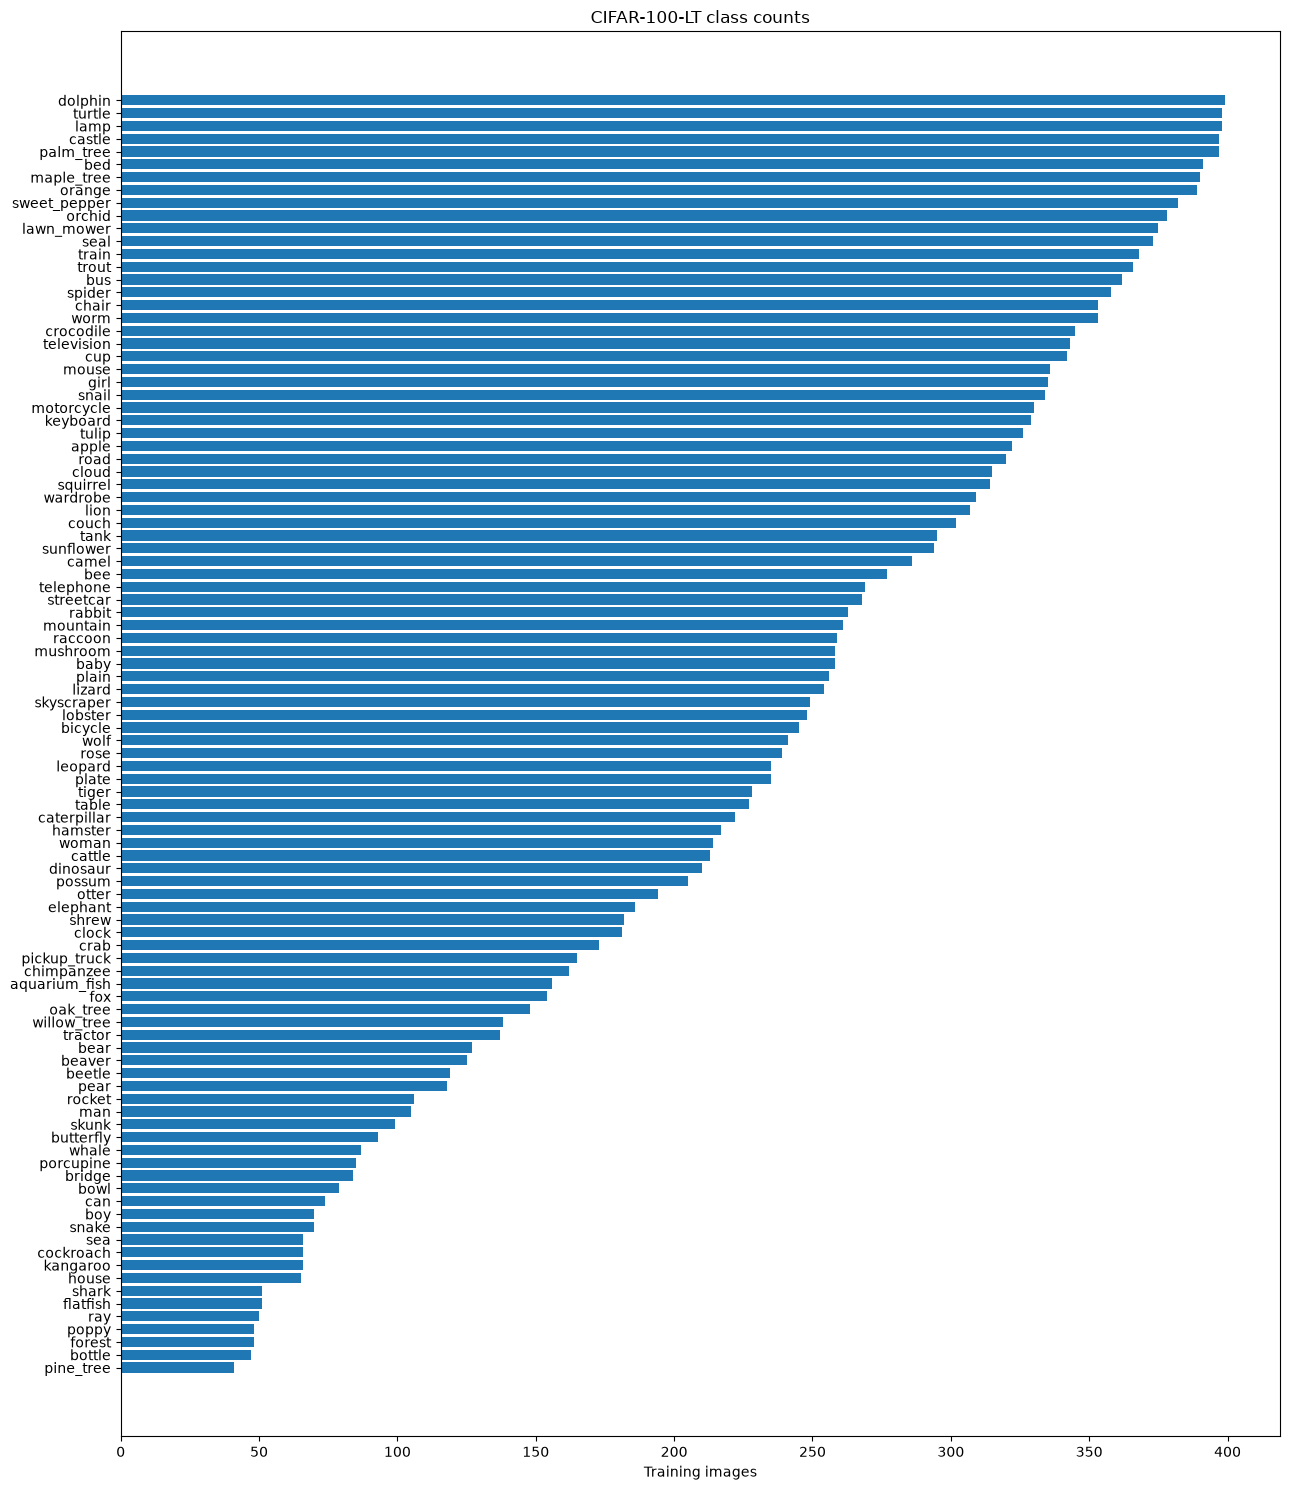

In [175]:
counts = train_pool['label'].value_counts().sort_values()
print('Smallest class:', counts.min(), 'images | Largest class:', counts.max(), 'images')
plt.figure(figsize=(13, 15))
plt.barh([str(x) for x in counts.index], counts.values)
plt.xlabel('Training images')
plt.title('CIFAR-100-LT class counts')
plt.tight_layout()
plt.show()

## 4. Classifier definitions and checkpointed training

Reuse the original CNN and CIFAR-sized ResNet-18, with the original fixed normalization, augmentation, AdamW and inverse-square-root weighted cross-entropy. The CNN is used only for the overlap experiment's OOF predictions. No classifier sees test images during fitting. Training inputs must belong to the fixed training split or the generated-image manifest. Each checkpoint records the training-data fingerprint, seed, architecture and epoch budget to reject accidental cross-run reuse.
Completed compatible classifiers return immediately without constructing a training loader or optimizer.


In [176]:
mean = (0.5071, 0.4867, 0.4408)
std = (0.2675, 0.2565, 0.2761)
train_transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])
test_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])


class CIFARDataset(Dataset):
    def __init__(self, table, transform):
        self.paths = [data_root / path for path in table['image_path']]
        self.labels = table['target'].tolist() if 'target' in table else [-1] * len(table)
        self.transform = transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, index):
        with Image.open(self.paths[index]) as image:
            image = image.convert('RGB')
        return self.transform(image), self.labels[index]


class SimpleCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(64, 128, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Flatten(),
            nn.Linear(128 * 4 * 4, 256), nn.ReLU(), nn.Dropout(0.3),
            nn.Linear(256, NUM_CLASSES),
        )

    def forward(self, x):
        return self.layers(x)


def make_model(kind):
    if kind == 'cnn':
        return SimpleCNN().to(DEVICE)
    model = models.resnet18(weights=None)
    model.conv1 = nn.Conv2d(3, 64, 3, stride=1, padding=1, bias=False)
    model.maxpool = nn.Identity()
    model.fc = nn.Linear(model.fc.in_features, NUM_CLASSES)
    return model.to(DEVICE)


def make_loader(table, training=False):
    transform = train_transform if training else test_transform
    return DataLoader(
        CIFARDataset(table, transform), batch_size=BATCH_SIZE,
        shuffle=training, num_workers=NUM_WORKERS,
        pin_memory=(DEVICE.type == 'cuda')
    )


def class_weights(table):
    counts = np.bincount(table['target'], minlength=NUM_CLASSES)
    weights = np.zeros(NUM_CLASSES, dtype=float)
    present = counts > 0
    weights[present] = 1 / np.sqrt(counts[present])
    weights[present] /= weights[present].mean()
    return torch.tensor(weights, dtype=torch.float32, device=DEVICE)

In [177]:
def assert_training_sources(data):
    paths = set(data['image_path'].map(lambda p: str((data_root / p).resolve())))
    allowed = real_training_paths
    if 'synthetic_pool' in globals():
        allowed = allowed.union(synthetic_pool['image_path'])
    if 'conventional_balanced_pool' in globals():
        allowed = allowed.union(conventional_balanced_pool['image_path'])
    if not paths.issubset(allowed):
        raise RuntimeError('Training input includes a path outside the authorized training pools.')

def train_model(kind, name, data, epochs, seed):
    assert_training_sources(data)
    signature = {
        'data_sha256': hashlib.sha256(
            data[['image_path', 'label', 'target']].to_csv(index=False).encode('utf-8')
        ).hexdigest(),
        'kind': kind, 'seed': seed, 'epochs': epochs,
        'settings_sha256': hashlib.sha256((SAVE_DIR / 'settings.json').read_bytes()).hexdigest(),
    }
    if name == 'final_resnet18_conventional_balanced':
        signature['conventional_augmentation_sha256'] = conventional_fingerprint
    set_seed(seed)
    model = make_model(kind)
    checkpoint = SAVE_DIR / 'checkpoints' / f'{name}.pt'
    history = []
    start_epoch = 0

    saved = None
    if checkpoint.is_file():
        saved = load_checkpoint(checkpoint, DEVICE)
        if saved.get('signature') != signature:
            raise RuntimeError(f'Checkpoint training inputs changed: {name}. Use a new local run directory.')
    elif ARCHIVE_COMPATIBLE and name.startswith('fold_'):
        archived = SOURCE_RUN / 'checkpoints' / f'{name}.pt'
        if archived.is_file():
            candidate = load_checkpoint(archived, DEVICE)
            legacy_signature = dict(signature)
            legacy_signature['data_sha256'] = hashlib.sha256(
                archived_real_table(data)[['image_path', 'label', 'target']].to_csv(index=False, lineterminator='\n').encode('utf-8')
            ).hexdigest()
            legacy_signature['settings_sha256'] = sha256_file(SOURCE_SETTINGS_FILE)
            if candidate.get('signature') == legacy_signature:
                saved = candidate
                # Rebase only the path-dependent signature after verifying the original.
                imported = dict(candidate, signature=signature,
                                imported_from={'sha256': sha256_file(archived), 'signature': legacy_signature})
                temp_path = checkpoint.with_suffix('.tmp')
                torch.save(imported, temp_path)
                os.replace(temp_path, checkpoint)
                del imported, candidate
                print(f'{name}: verified archived checkpoint')
            else:
                print(f'{name}: archived checkpoint signature mismatch; training from scratch')
    if saved is not None:
        model.load_state_dict(saved['model'])
        history = saved['history']
        start_epoch = saved['epoch']
        if not 0 <= start_epoch <= epochs:
            raise RuntimeError(f'Invalid checkpoint epoch: {name}')
        if start_epoch == epochs:
            print(f'{name}: loaded complete checkpoint; skipping training')
            pd.DataFrame(history).to_csv(SAVE_DIR / 'results' / f'{name}_training.csv', index=False)
            return model
        print(f'{name}: resuming at epoch {start_epoch}/{epochs}')
    else:
        print(f'{name}: no compatible checkpoint; training from scratch')
    optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATES[kind], weight_decay=0.01)
    if saved is not None:
        optimizer.load_state_dict(saved['optimizer'])
        del saved
    loss_fn = nn.CrossEntropyLoss(weight=class_weights(data))
    loader = make_loader(data, training=True)

    for epoch in range(start_epoch, epochs):
        # Fixed per-epoch seed also makes checkpoint restarts reproducible.
        set_seed(seed + epoch + 1)
        model.train()
        total_loss = 0.0
        correct = 0
        seen = 0

        for images, labels in tqdm(loader, desc=f'{name}: epoch {epoch+1}/{epochs}', leave=False):
            images = images.to(DEVICE)
            labels = labels.to(DEVICE)
            optimizer.zero_grad()
            outputs = model(images)
            loss = loss_fn(outputs, labels)
            loss.backward()
            optimizer.step()

            total_loss += loss.item() * len(labels)
            correct += (outputs.argmax(1) == labels).sum().item()
            seen += len(labels)

        row = {'epoch': epoch + 1, 'loss': total_loss / seen, 'accuracy': correct / seen}
        history.append(row)
        print(f"{name}: epoch {epoch+1}/{epochs} | loss {row['loss']:.4f} | accuracy {row['accuracy']:.4f}")

        # Save without risking an incomplete final checkpoint.
        temp_path = checkpoint.with_suffix('.tmp')
        torch.save({'model': model.state_dict(), 'optimizer': optimizer.state_dict(),
                    'epoch': epoch + 1, 'history': history, 'signature': signature}, temp_path)
        os.replace(temp_path, checkpoint)

    pd.DataFrame(history).to_csv(SAVE_DIR / 'results' / f'{name}_training.csv', index=False)
    return model


@torch.inference_mode()
def predict_probs(model, data):
    if len(data) == 0:
        return np.empty((0, NUM_CLASSES), dtype=np.float32)
    model.eval()
    predictions = []
    for images, _ in make_loader(data):
        outputs = model(images.to(DEVICE))
        predictions.append(outputs.softmax(dim=1).cpu().numpy())
    return np.concatenate(predictions)


def free_model(model):
    model.to('cpu')  # Release the model's GPU weights before clearing the cache.
    gc.collect()
    if DEVICE.type == 'cuda':
        torch.cuda.empty_cache()
    elif DEVICE.type == 'mps':
        torch.mps.empty_cache()

third_name = ('diffusion_real_only_control' if REPEAT_MODE == 'baseline_repeat'
              else 'filtered_plus_synthetic')
EXPERIMENT_NAMES = ('original_real_only', 'original_overlap_rejected', third_name,
                    'synthetic_only', 'real_plus_synthetic', 'conventional_balanced')
EXPERIMENT_SEEDS = {name: SEED + 400 for name in EXPERIMENT_NAMES}
if REPEAT_MODE == 'baseline_repeat':
    EXPERIMENT_SEEDS[third_name] = SEED + 401
COMPLETION = SAVE_DIR / 'checkpoints' / 'all_experiments_complete.json'


def verified_final_record(run, version, archived=False):
    """Validate an existing final checkpoint against its own training provenance."""
    name = f'final_resnet18_{version}'
    checkpoint = run / 'checkpoints' / f'{name}.pt'
    manifest = run / 'splits' / 'experiments' / f'{version}.csv'
    if not checkpoint.is_file() or not manifest.is_file():
        return None
    cfg = archive_settings if archived else settings
    cfg_file = run / 'settings.json'
    if not cfg_file.is_file():
        return None
    cfg_sha = sha256_file(cfg_file)
    if json.loads(cfg_file.read_text()) != cfg:
        return None
    table = pd.read_csv(require_materialized(manifest), dtype={'label': 'string'})
    if list(table.columns) != ['image_path', 'label', 'target', 'source']:
        raise RuntimeError(f'Unexpected training manifest format: {manifest}')
    if not table['image_path'].is_unique or not table['label'].map(class_to_id).eq(table['target']).all():
        raise RuntimeError(f'Invalid paths or labels: {manifest}')
    train = archive_train if archived else train_pool
    # Use the exact original split namespace for archived paths.
    test_paths = (set(archive_test['image_path']) if archived else
                  set(pd.read_csv(TEST_MANIFEST, dtype={'label': 'string'})['image_path']))
    real_map = train.set_index('image_path')['target']
    real = table.loc[table['source'].eq('real')]
    if (not set(real['image_path']).issubset(real_map.index)
            or not real['image_path'].map(real_map).eq(real['target']).all()
            or not set(table['image_path']).isdisjoint(test_paths)):
        raise RuntimeError(f'Invalid real training membership / test leakage: {manifest}')
    expected_sources = {
        'original_real_only': {'real'}, 'original_overlap_rejected': {'real'},
        'diffusion_real_only_control': {'real'}, 'filtered_plus_synthetic': {'real', 'synthetic'},
        'synthetic_only': {'synthetic'}, 'real_plus_synthetic': {'real', 'synthetic'},
        'conventional_balanced': {'real', 'conventional_augmentation'},
    }
    if set(table['source']) != expected_sources[version]:
        raise RuntimeError(f'Unexpected training source: {manifest}')
    if version in ('original_real_only', 'diffusion_real_only_control', 'real_plus_synthetic',
                   'conventional_balanced') and set(real['image_path']) != set(real_map.index):
        raise RuntimeError(f'Original real training pool incomplete: {manifest}')
    saved = load_checkpoint(checkpoint)
    sig = saved.get('signature', {})
    expected = {'data_sha256': hashlib.sha256(table[['image_path', 'label', 'target']]
                .to_csv(index=False, lineterminator='\n' if archived else os.linesep).encode('utf-8')).hexdigest(),
                'kind': 'resnet18', 'seed': EXPERIMENT_SEEDS[version],
                'epochs': FINAL_EPOCHS, 'settings_sha256': cfg_sha}
    if any(sig.get(k) != v for k, v in expected.items()) or saved.get('epoch') != FINAL_EPOCHS:
        return None
    aug_sha = None
    if version == 'conventional_balanced':
        aug_sha = sig.get('conventional_augmentation_sha256')
        matches = [p for p in (run / 'conventional_augmented').glob('*/augmentation_manifest.json')
                   if sha256_file(p) == aug_sha]
        if len(matches) != 1:
            raise RuntimeError('Missing original conventional-augmentation provenance.')
        aug = json.loads(matches[0].read_text())
        aug_rows = aug['images']
        added = table.loc[table['source'].eq('conventional_augmentation')]
        if ({r['image_path']: r['target'] for r in aug_rows}
                != dict(zip(added['image_path'], added['target']))
                or any(r['source_path'] not in real_map.index
                       or int(real_map.loc[r['source_path']]) != r['target'] for r in aug_rows)
                or aug['config']['train_split_sha256'] != cfg['train_split_sha256']):
            raise RuntimeError('Conventional augmentation source provenance mismatch.')
    # Check state-dict compatibility before accepting a checkpoint.
    model = make_model('resnet18')
    model.load_state_dict(saved['model'], strict=True)
    free_model(model)
    del model, saved
    record = {'data': version, 'checkpoint': checkpoint.name, 'sha256': sha256_file(checkpoint),
              'epochs': FINAL_EPOCHS, 'seed': EXPERIMENT_SEEDS[version],
              'training_manifest_sha256': sha256_file(manifest), 'train_images': len(table),
              'optimizer_updates': FINAL_EPOCHS * math.ceil(len(table) / BATCH_SIZE),
              'checkpoint_settings_sha256': cfg_sha,
              'checkpoint_origin': 'archive' if archived else 'local'}
    if aug_sha is not None:
        record['conventional_augmentation_sha256'] = aug_sha
    # When available, check against the original frozen completion record as well.
    completion = run / 'checkpoints' / 'all_experiments_complete.json'
    if archived and completion.is_file():
        frozen_old = json.loads(require_materialized(completion).read_text())
        if (frozen_old['settings_sha256'] != cfg_sha
                or frozen_old['train_split_sha256'] != cfg['train_split_sha256']
                or frozen_old['test_split_sha256'] != cfg['test_split_sha256']):
            raise RuntimeError('Archived completion settings/split mismatch.')
        old = next((r for r in frozen_old['experiments'] if r['data'] == version), None)
        if old is None or any(record.get(k) != v for k, v in old.items()
                              if k in record and k not in ('checkpoint_origin', 'checkpoint_settings_sha256')):
            raise RuntimeError(f'Archived completion record mismatch: {version}')
    return record


reusable_finals = {}
for version in EXPERIMENT_NAMES:
    if FORCE_RETRAIN:
        break
    # A completed local model is preferred; otherwise use the verified published model.
    record = verified_final_record(SAVE_DIR, version)
    if record is None and ARCHIVE_COMPATIBLE:
        record = verified_final_record(SOURCE_RUN, version, archived=True)
    if record is not None:
        reusable_finals[version] = record
        print(f'{version}: verified {record["checkpoint_origin"]} checkpoint; no retraining needed')
    else:
        print(f'{version}: no complete compatible checkpoint')
REUSE_ALL_FINALS = len(reusable_finals) == len(EXPERIMENT_NAMES)
if REUSE_ALL_FINALS:
    print('All six final classifiers are available. Skip OOF, diffusion and augmentation; evaluate directly.')


original_real_only: verified archive checkpoint; no retraining needed
original_overlap_rejected: verified archive checkpoint; no retraining needed
diffusion_real_only_control: verified archive checkpoint; no retraining needed
synthetic_only: verified archive checkpoint; no retraining needed
real_plus_synthetic: verified archive checkpoint; no retraining needed
conventional_balanced: verified archive checkpoint; no retraining needed
All six final classifiers are available. Skip OOF, diffusion and augmentation; evaluate directly.


## 5. Original overlap rejection: five stratified folds

The **four fold numbers per model are sampled with replacement**. For example, `[1, 1, 3, 5]` means the model trains twice on fold 1 and once each on folds 3 and 5; it **never saw folds 2 and 4**.

We retry a random draw until every fold has at least one eligible CNN and one eligible ResNet, and each model sees at least three different folds. This is necessary to ensure that every image can receive two genuine out-of-fold predictions.

All folds are created exclusively from the 80% training partition. The held-out test set is not a sixth fold and is never used for OOF predictions.

In [178]:
if not REUSE_ALL_FINALS:
    # Give each image one of five fold numbers (0, 1, 2, 3, or 4).
    fold_id = np.full(len(train_pool), -1, dtype=int)
    splitter = StratifiedKFold(n_splits=FOLDS, shuffle=True, random_state=SEED)
    for fold, (_, held_out) in enumerate(splitter.split(train_pool, train_pool['target'])):
        fold_id[held_out] = fold
    fold_rows = [np.where(fold_id == fold)[0] for fold in range(FOLDS)]

    # Sample training folds WITH replacement, ensuring every held-out fold is covered.
    rng = np.random.default_rng(SEED)
    plans = {}
    for kind in ['cnn', 'resnet18']:
        for _ in range(50000):
            draws = rng.integers(0, FOLDS, size=(MODELS_EACH, DRAWS_PER_MODEL))
            enough_variety = all(len(set(row)) >= 3 for row in draws)
            all_folds_covered = all(any(fold not in row for row in draws) for fold in range(FOLDS))
            if enough_variety and all_folds_covered:
                plans[kind] = draws
                break
        else:
            raise RuntimeError(f'Could not generate an eligible fold plan for {kind}.')

    # Randomly choose one eligible CNN and one eligible ResNet FOR EACH IMAGE.
    selected = {}
    for kind in ['cnn', 'resnet18']:
        selected[kind] = np.full(len(train_pool), -1, dtype=int)
        for fold in range(FOLDS):
            eligible = [m for m in range(MODELS_EACH) if fold not in plans[kind][m]]
            selected[kind][fold_rows[fold]] = rng.choice(eligible, size=len(fold_rows[fold]))

        # A selected model must NEVER train on the image's fold.
        for m in range(MODELS_EACH):
            image_folds = fold_id[selected[kind] == m]
            assert not np.isin(image_folds, plans[kind][m]).any(), 'Fold leakage detected!'

    for kind, draws in plans.items():
        for m, row in enumerate(draws):
            print(f'{kind} {m+1}: training folds {row.tolist()}')

    (SAVE_DIR / 'results' / 'fold_sampling_plan.json').write_text(
        json.dumps({kind: draws.tolist() for kind, draws in plans.items()}, indent=2)
    )
    assignments = train_pool[['image_path', 'label']].copy()
    assignments['fold'] = fold_id + 1
    assignments['chosen_cnn'] = selected['cnn'] + 1
    assignments['chosen_resnet18'] = selected['resnet18'] + 1
    assignments.to_csv(SAVE_DIR / 'results' / 'image_model_assignments.csv', index=False)
    print('All images have two valid out-of-fold model assignments.')
else:
    print("All six final checkpoints verified; skipping this preparation stage.")


All six final checkpoints verified; skipping this preparation stage.


## 6. Train the ten OOF models and collect training-only predictions

The model only predicts for the images **assigned to it**. Predictions are cached to disk, so a rerun can skip completed models. A cache entry records its image indices, labels, and training folds for safety.

The same five CNNs and five ResNet-18s, fold bootstrapping with replacement, 12-epoch defaults and assignment policy are retained. Only predictions on training-pool rows omitted from that model's training folds are collected.
Skipped entirely when all final classifiers are already verified.


In [179]:
if not REUSE_ALL_FINALS:
    oof_probs = {
        'cnn': np.full((len(train_pool), NUM_CLASSES), np.nan, dtype=np.float32),
        'resnet18': np.full((len(train_pool), NUM_CLASSES), np.nan, dtype=np.float32),
    }

    for kind in ['cnn', 'resnet18']:
        for m in range(MODELS_EACH):
            draws = plans[kind][m]
            name = f'fold_{kind}_{m+1}'
            # Concatenation repeats a fold if it was sampled twice.
            training_indices = np.concatenate([fold_rows[f] for f in draws])
            prediction_indices = np.where(selected[kind] == m)[0]
            assert not np.isin(fold_id[prediction_indices], draws).any()

            training_data = train_pool.iloc[training_indices].reset_index(drop=True)
            prediction_data = train_pool.iloc[prediction_indices].reset_index(drop=True)
            cache = SAVE_DIR / 'oof' / f'{name}.npz'

            fold_checkpoint = SAVE_DIR / 'checkpoints' / f'{name}.pt'
            cache_valid = False
            if cache.is_file() and fold_checkpoint.is_file():
                require_materialized(cache)
                with np.load(cache) as cached:
                    cache_valid = ('checkpoint_sha256' in cached.files and
                                   str(cached['checkpoint_sha256'].item()) == sha256_file(fold_checkpoint))
            if cache_valid:
                with np.load(cache) as saved:
                    assert np.array_equal(saved['indices'], prediction_indices)
                    assert np.array_equal(saved['labels'], prediction_data['target'].to_numpy())
                    assert np.array_equal(saved['draws'], draws)
                    assert np.array_equal(saved['paths'], prediction_data['image_path'].to_numpy(dtype=str))
                    probs = saved['probs']
                print(name, ': cached predictions loaded')
            else:
                print(f'{name}: train {len(training_data)} rows, predict {len(prediction_data)} held-out rows')
                model = train_model(kind, name, training_data, FOLD_EPOCHS,
                                    seed=SEED + (100 if kind == 'cnn' else 200) + m)
                probs = predict_probs(model, prediction_data)
                # Atomic NPZ save, so interrupted writes cannot damage the old cache.
                temp_cache = cache.with_suffix('.tmp.npz')
                np.savez_compressed(temp_cache, indices=prediction_indices,
                                    labels=prediction_data['target'].to_numpy(),
                                    draws=draws, probs=probs, paths=prediction_data['image_path'].to_numpy(dtype=str),
                                    checkpoint_sha256=sha256_file(fold_checkpoint))
                os.replace(temp_cache, cache)
                free_model(model)
                del model

            assert probs.shape == (len(prediction_indices), NUM_CLASSES)
            oof_probs[kind][prediction_indices] = probs

    for kind in ['cnn', 'resnet18']:
        assert np.isfinite(oof_probs[kind]).all(), f'Missing OOF predictions for {kind}'
        assert np.allclose(oof_probs[kind].sum(axis=1), 1, atol=0.001)
    print('Both out-of-fold probability tables are complete.')
else:
    print("All six final checkpoints verified; skipping this preparation stage.")


All six final checkpoints verified; skipping this preparation stage.


## 7. Apply the original overlap rejection rule

An image is a rejection candidate when both assigned models predict the wrong class and each assigns a probability of 0.05 or less to the image's true class. Candidates are ranked within their class by low average true-class probability. At most 10% of examples from a class are removed, and at least five images from each class are retained. This produces the filtered training pool.

This procedure identifies examples that both models find difficult; it does not establish that the removed images have incorrect labels.

**Simple confidence rule:** reject a candidate only if both chosen models (a) predict the wrong class and (b) each assign the true label a probability of at most `TRUE_PROB_THRESHOLD`.

Even when many images satisfy that rule, reject no more than `MAX_REJECT_PER_CLASS` of each class and keep at least `MIN_KEEP_PER_CLASS`. This protects rare classes on the long-tailed dataset.

Only the original training pool is filtered. The diffusion model will still learn from the complete original training pool, not the filtered subset. No test images or test scores influence rejection.

In [180]:
if not REUSE_ALL_FINALS:
    true_labels = train_pool['target'].to_numpy()
    indices = np.arange(len(train_pool))
    cnn_probs = oof_probs['cnn']
    resnet_probs = oof_probs['resnet18']

    cnn_pred = cnn_probs.argmax(axis=1)
    resnet_pred = resnet_probs.argmax(axis=1)
    cnn_true_prob = cnn_probs[indices, true_labels]
    resnet_true_prob = resnet_probs[indices, true_labels]

    both_wrong = (cnn_pred != true_labels) & (resnet_pred != true_labels)
    low_confidence = (cnn_true_prob <= TRUE_PROB_THRESHOLD) & (
        resnet_true_prob <= TRUE_PROB_THRESHOLD)
    candidates = both_wrong & low_confidence

    # Sort eligible candidates by the two models' average probability of the true class.
    risk = 1 - (cnn_true_prob + resnet_true_prob) / 2
    rejected = np.zeros(len(train_pool), dtype=bool)
    for label in range(NUM_CLASSES):
        class_rows = np.where(true_labels == label)[0]
        class_candidates = class_rows[candidates[class_rows]]
        max_remove = min(
            int(len(class_rows) * MAX_REJECT_PER_CLASS),
            len(class_rows) - MIN_KEEP_PER_CLASS
        )
        max_remove = max(0, max_remove)
        worst_first = class_candidates[np.argsort(-risk[class_candidates])]
        rejected[worst_first[:max_remove]] = True

    filtered_pool = train_pool.loc[~rejected].reset_index(drop=True)
    print('Both models wrong:', both_wrong.sum())
    print('Confidence-based candidates:', candidates.sum())
    print('Rejected:', rejected.sum())
    print('Original:', len(train_pool), '| Filtered:', len(filtered_pool))

    review = assignments.copy()
    review['cnn_prediction'] = [class_names[i] for i in cnn_pred]
    review['resnet_prediction'] = [class_names[i] for i in resnet_pred]
    review['cnn_confidence'] = cnn_probs.max(axis=1)
    review['resnet_confidence'] = resnet_probs.max(axis=1)
    review['cnn_true_class_probability'] = cnn_true_prob
    review['resnet_true_class_probability'] = resnet_true_prob
    review['both_wrong'] = both_wrong
    review['candidate'] = candidates
    review['rejected'] = rejected
    review.to_csv(SAVE_DIR / 'results' / 'oof_confidence_and_rejection.csv', index=False)
    review.loc[rejected].to_csv(SAVE_DIR / 'results' / 'rejected_examples.csv', index=False)
    filtered_pool.to_csv(SAVE_DIR / 'results' / 'filtered_training_pool.csv', index=False)

    before = np.bincount(true_labels, minlength=NUM_CLASSES)
    after = np.bincount(filtered_pool['target'], minlength=NUM_CLASSES)
    rejection_by_class = pd.DataFrame({
        'class': class_names, 'original': before, 'filtered': after,
        'removed': before - after
    })
    rejection_by_class.to_csv(SAVE_DIR / 'results' / 'rejection_by_class.csv', index=False)
    print(rejection_by_class.sort_values('removed', ascending=False).head(10).to_string(index=False))

    plt.figure(figsize=(5, 4))
    plt.bar(['Retained', 'Rejected'], [len(filtered_pool), int(rejected.sum())])
    plt.title('Confidence-based filtering')
    plt.ylabel('Images')
    plt.tight_layout()
    plt.show()
    assert set(filtered_pool['image_path']).issubset(real_training_paths)
    assert filtered_pool['target'].nunique() == NUM_CLASSES
    assert len(filtered_pool) + int(rejected.sum()) == len(train_pool)
    filtered_real_pool = filtered_pool.assign(source='real')
else:
    print("All six final checkpoints verified; skipping this preparation stage.")


All six final checkpoints verified; skipping this preparation stage.


## 8. Conditional diffusion U-Net

The forward process samples Gaussian noise at a random time:
`x_t = sqrt(alpha_bar[t]) * x_0 + sqrt(1-alpha_bar[t]) * epsilon`.
The network predicts epsilon given the noisy image, time index, and integer class label. A sinusoidal time embedding and a learned class embedding condition every residual block. The objective is mean squared error between predicted and actual noise. Images are scaled to [-1, 1]; classifier normalization is applied separately later.

A cosine noise schedule and EMA of the model weights are used for sampling. The U-Net has skip connections at resolutions 32, 16 and 8.

In [181]:
diffusion_transform = transforms.Compose([
    transforms.Resize((32, 32)),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize((0.5,)*3, (0.5,)*3),
])

class DiffusionDataset(Dataset):
    def __init__(self, table):
        self.paths = [data_root / p for p in table['image_path']]
        self.targets = table['target'].astype(int).tolist()

    def __len__(self):
        return len(self.targets)

    def __getitem__(self, index):
        with Image.open(self.paths[index]) as img:
            x = diffusion_transform(img.convert('RGB'))
        return x, self.targets[index]

def sinusoidal_time(t, dim):
    half = dim // 2
    frequencies = torch.exp(
        -math.log(10000) * torch.arange(half, device=t.device, dtype=torch.float32)
        / max(half - 1, 1)
    )
    angles = t.float()[:, None] * frequencies[None, :]
    return torch.cat([angles.sin(), angles.cos()], dim=1)

class ConditionalBlock(nn.Module):
    def __init__(self, in_channels, out_channels, embedding_dim):
        super().__init__()
        self.norm1 = nn.GroupNorm(8, in_channels)
        self.conv1 = nn.Conv2d(in_channels, out_channels, 3, padding=1)
        self.cond = nn.Linear(embedding_dim, 2 * out_channels)
        self.norm2 = nn.GroupNorm(8, out_channels)
        self.conv2 = nn.Conv2d(out_channels, out_channels, 3, padding=1)
        self.skip = (nn.Identity() if in_channels == out_channels
                     else nn.Conv2d(in_channels, out_channels, 1))
        self.act = nn.SiLU()

    def forward(self, x, emb):
        h = self.conv1(self.act(self.norm1(x)))
        scale, shift = self.cond(self.act(emb)).chunk(2, dim=1)
        h = self.norm2(h) * (1 + scale[:, :, None, None]) + shift[:, :, None, None]
        return self.skip(x) + self.conv2(self.act(h))

class ConditionalUNet(nn.Module):
    def __init__(self, num_classes, width=48):
        super().__init__()
        w, e = width, 4 * width
        self.embedding_dim = e
        self.time_mlp = nn.Sequential(nn.Linear(e, e), nn.SiLU(), nn.Linear(e, e))
        self.class_embedding = nn.Embedding(num_classes, e)
        self.input_conv = nn.Conv2d(3, w, 3, padding=1)
        self.enc1 = ConditionalBlock(w, w, e)
        self.down1 = nn.Conv2d(w, 2*w, 4, stride=2, padding=1)
        self.enc2 = ConditionalBlock(2*w, 2*w, e)
        self.down2 = nn.Conv2d(2*w, 4*w, 4, stride=2, padding=1)
        self.enc3 = ConditionalBlock(4*w, 4*w, e)
        self.mid1 = ConditionalBlock(4*w, 4*w, e)
        self.mid2 = ConditionalBlock(4*w, 4*w, e)
        self.dec3 = ConditionalBlock(8*w, 4*w, e)
        self.up2 = nn.Sequential(nn.Upsample(scale_factor=2, mode='nearest'),
                                 nn.Conv2d(4*w, 2*w, 3, padding=1))
        self.dec2 = ConditionalBlock(4*w, 2*w, e)
        self.up1 = nn.Sequential(nn.Upsample(scale_factor=2, mode='nearest'),
                                 nn.Conv2d(2*w, w, 3, padding=1))
        self.dec1 = ConditionalBlock(2*w, w, e)
        self.output = nn.Sequential(nn.GroupNorm(8, w), nn.SiLU(),
                                    nn.Conv2d(w, 3, 3, padding=1))

    def forward(self, x, t, y):
        emb = self.time_mlp(sinusoidal_time(t, self.embedding_dim)) + self.class_embedding(y)
        h1 = self.enc1(self.input_conv(x), emb)
        h2 = self.enc2(self.down1(h1), emb)
        h3 = self.enc3(self.down2(h2), emb)
        h = self.mid2(self.mid1(h3, emb), emb)
        h = self.dec3(torch.cat([h, h3], dim=1), emb)
        h = self.dec2(torch.cat([self.up2(h), h2], dim=1), emb)
        h = self.dec1(torch.cat([self.up1(h), h1], dim=1), emb)
        return self.output(h)

def cosine_alpha_bar(steps, device):
    grid = torch.linspace(0, steps, steps + 1, dtype=torch.float64) / steps
    curve = torch.cos((grid + 0.008) / 1.008 * math.pi / 2).square()
    curve = curve / curve[0]
    beta = (1 - curve[1:] / curve[:-1]).clamp(1e-5, 0.999)
    return (1 - beta).cumprod(dim=0).float().to(device)

alpha_bar = cosine_alpha_bar(DIFFUSION_TIMESTEPS, DEVICE)

def add_noise(x0, t, noise):
    a = alpha_bar[t].view(-1, 1, 1, 1)
    return a.sqrt() * x0 + (1 - a).sqrt() * noise

# Lightweight shape, gradient and schedule check before expensive training.
set_seed(SEED)
check_model = ConditionalUNet(NUM_CLASSES, DIFFUSION_WIDTH).to(DEVICE)
x_check = torch.randn(2, 3, 32, 32, device=DEVICE)
t_check = torch.tensor([0, DIFFUSION_TIMESTEPS-1], device=DEVICE)
y_check = torch.tensor([0, NUM_CLASSES-1], device=DEVICE)
prediction = check_model(add_noise(x_check, t_check, x_check), t_check, y_check)
assert prediction.shape == x_check.shape and torch.isfinite(prediction).all()
prediction.square().mean().backward()
assert check_model.class_embedding.weight.grad is not None
assert (alpha_bar[1:] < alpha_bar[:-1]).all()
del check_model, prediction, x_check, t_check, y_check
print('Diffusion forward/backward and schedule checks passed.')

Diffusion forward/backward and schedule checks passed.


## 9. Train the diffusion model

Sample a time step and independent noise for each real image, then optimize the conditional noise predictor. Checkpoints include optimizer, EMA, AMP scaler and history. EMA is updated after successful optimizer steps. The training objective is denoising loss, not classification accuracy.

In [182]:
def atomic_torch_save(payload, path):
    temp = path.with_suffix('.tmp')
    torch.save(payload, temp)
    os.replace(temp, path)

def diffusion_loader():
    dataset = DiffusionDataset(train_pool)
    sampler = None
    if BALANCED_DIFFUSION:
        counts = np.bincount(dataset.targets, minlength=NUM_CLASSES)
        assert (counts > 0).all()
        weights = torch.tensor(1.0 / counts[np.asarray(dataset.targets)], dtype=torch.double)
        sampler = WeightedRandomSampler(weights, len(dataset), replacement=True)
    return DataLoader(dataset, batch_size=DIFFUSION_BATCH_SIZE,
                      sampler=sampler, shuffle=sampler is None,
                      num_workers=NUM_WORKERS, pin_memory=DEVICE.type == 'cuda')

def train_diffusion():
    set_seed(SEED + 500)
    model = ConditionalUNet(NUM_CLASSES, DIFFUSION_WIDTH).to(DEVICE)
    ema = deepcopy(model).eval().requires_grad_(False)
    path = SAVE_DIR / 'checkpoints' / 'conditional_diffusion.pt'
    history, start = [], 0
    saved = None
    if path.is_file():
        saved = load_checkpoint(path, DEVICE)
    elif ARCHIVE_COMPATIBLE:
        archived = SOURCE_RUN / 'checkpoints' / 'conditional_diffusion.pt'
        if archived.is_file():
            saved = load_checkpoint(archived, DEVICE)
            # Legacy diffusion weights have no per-checkpoint signature; the run settings and
            # exact training split were verified above. Keep the source file intact.
            shutil.copy2(archived, path)
            print('Using archived conditional diffusion checkpoint')
    if saved is not None:
        model.load_state_dict(saved['model'])
        ema.load_state_dict(saved['ema'])
        start, history = saved['epoch'], saved['history']
        if not 0 <= start <= DIFFUSION_EPOCHS:
            raise RuntimeError('Diffusion checkpoint epoch is incompatible with settings.')
        if start == DIFFUSION_EPOCHS:
            print('Diffusion checkpoint complete; skipping training.')
            pd.DataFrame(history).to_csv(SAVE_DIR / 'results' / 'diffusion_training.csv', index=False)
            return ema.eval()
        print(f'Resuming diffusion at epoch {start}/{DIFFUSION_EPOCHS}')
    else:
        print('No compatible diffusion checkpoint; training from scratch.')
    optimizer = torch.optim.AdamW(model.parameters(), lr=DIFFUSION_LR, weight_decay=0.01)
    amp = DEVICE.type == 'cuda'
    scaler = torch.amp.GradScaler('cuda', enabled=amp)
    if saved is not None:
        optimizer.load_state_dict(saved['optimizer'])
        if amp and saved.get('scaler'):
            scaler.load_state_dict(saved['scaler'])
        del saved
    loader = diffusion_loader()

    for epoch in range(start, DIFFUSION_EPOCHS):
        set_seed(SEED + 501 + epoch)
        model.train()
        total, seen = 0.0, 0
        for x0, y in tqdm(loader, desc=f'Diffusion {epoch+1}/{DIFFUSION_EPOCHS}', leave=False):
            x0, y = x0.to(DEVICE), y.to(DEVICE)
            t = torch.randint(0, DIFFUSION_TIMESTEPS, (len(y),), device=DEVICE)
            noise = torch.randn_like(x0)
            xt = add_noise(x0, t, noise)
            optimizer.zero_grad(set_to_none=True)
            with (torch.autocast('cuda', dtype=torch.float16) if amp else nullcontext()):
                pred = model(xt, t, y)
                loss = nn.functional.mse_loss(pred.float(), noise)
            if not torch.isfinite(loss):
                raise FloatingPointError('Non-finite diffusion loss')
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            previous_scale = scaler.get_scale()
            scaler.step(optimizer)
            scaler.update()
            if scaler.get_scale() >= previous_scale:
                with torch.no_grad():
                    for avg, current in zip(ema.parameters(), model.parameters()):
                        avg.lerp_(current.detach(), 1 - EMA_DECAY)
            total += loss.item() * len(y)
            seen += len(y)
        row = {'epoch': epoch+1, 'noise_mse': total / seen}
        history.append(row)
        print(f"Diffusion epoch {epoch+1}: MSE {row['noise_mse']:.5f}")
        atomic_torch_save({'model': model.state_dict(), 'ema': ema.state_dict(),
                           'optimizer': optimizer.state_dict(), 'scaler': scaler.state_dict(),
                           'epoch': epoch+1, 'history': history}, path)

    pd.DataFrame(history).to_csv(SAVE_DIR / 'results' / 'diffusion_training.csv', index=False)
    del model, optimizer
    return ema.eval()

if not REUSE_ALL_FINALS:
    diffusion_model = train_diffusion()
    loss_history = pd.read_csv(SAVE_DIR / 'results' / 'diffusion_training.csv')
    plt.plot(loss_history['epoch'], loss_history['noise_mse'])
    plt.xlabel('Epoch')
    plt.ylabel('Noise prediction MSE')
    plt.title('Conditional diffusion training')
    plt.show()
else:
    print("All six final checkpoints verified; skipping this preparation stage.")


All six final checkpoints verified; skipping this preparation stage.


## 10. Generate new images separately for every class

Use deterministic DDIM reverse sampling (eta=0) from independent Gaussian noise with the class label fixed throughout each reverse trajectory. The default produces exactly 200 images per class, 20,000 in total. Class labels are the requested conditions, not verified human annotations; synthetic images may be poor or mislabeled visually.

PNG batches are reproducibly generated and a manifest records every image, class ID and label. Existing complete batches are reused only when the trained checkpoint and generation settings are unchanged. Inspect the contact sheet before interpreting classifier scores.

In [183]:
@torch.inference_mode()
def sample_class(model, class_id, n):
    model.eval()
    x = torch.randn(n, 3, 32, 32, device=DEVICE)
    y = torch.full((n,), class_id, device=DEVICE, dtype=torch.long)
    steps = torch.linspace(DIFFUSION_TIMESTEPS-1, 0, SAMPLE_STEPS).round().long().tolist()
    for i, step in enumerate(steps):
        t = torch.full((n,), step, device=DEVICE, dtype=torch.long)
        a = alpha_bar[step]
        next_a = alpha_bar[steps[i+1]] if i+1 < len(steps) else a.new_tensor(1.0)
        noise = model(x, t, y)
        x0 = ((x - (1-a).sqrt() * noise) / a.sqrt()).clamp(-1, 1)
        # Recompute epsilon after clipping to preserve the DDIM decomposition.
        noise = (x - a.sqrt() * x0) / (1-a).sqrt()
        x = next_a.sqrt() * x0 + (1-next_a).sqrt() * noise
    if not torch.isfinite(x).all():
        raise FloatingPointError(f'Non-finite generated images for class {class_id}')
    return ((x.clamp(-1, 1) + 1) * 127.5).round().to(torch.uint8).cpu()

def generate_all_classes(model):
    # Guard against reusing images from different trained weights.
    checkpoint = SAVE_DIR / 'checkpoints' / 'conditional_diffusion.pt'
    with checkpoint.open('rb') as f:
        digest = hashlib.file_digest(f, 'sha256').hexdigest()
    fingerprint = SAVE_DIR / 'generated' / 'checkpoint_sha256.txt'
    if fingerprint.exists() and fingerprint.read_text().strip() != digest:
        raise RuntimeError('Diffusion checkpoint changed. Use a new SAVE_DIR; do not mix images.')
    if not fingerprint.exists():
        if any((SAVE_DIR / 'generated').glob('*/*.png')):
            raise RuntimeError('Untracked generated images exist. Use a new SAVE_DIR.')
        fingerprint.write_text(digest)

    records = []
    for label in tqdm(range(NUM_CLASSES), desc='Generating each class'):
        class_dir = SAVE_DIR / 'generated' / f'class_{label:03d}'
        class_dir.mkdir(exist_ok=True)
        for start in range(0, IMAGES_PER_CLASS, SAMPLE_BATCH_SIZE):
            stop = min(start + SAMPLE_BATCH_SIZE, IMAGES_PER_CLASS)
            paths = [class_dir / f'{i:05d}.png' for i in range(start, stop)]
            if not all(p.is_file() for p in paths):
                set_seed(SEED + 10000 + label * 100000 + start)
                batch = sample_class(model, label, len(paths))
                for pixels, path in zip(batch, paths):
                    temp = path.with_suffix('.tmp.png')
                    Image.fromarray(pixels.permute(1, 2, 0).numpy()).save(temp)
                    os.replace(temp, path)
            records.extend({'image_path': str(p.resolve()), 'label': class_names[label],
                            'target': label, 'source': 'synthetic'} for p in paths)
    table = pd.DataFrame(records)
    assert table['image_path'].is_unique
    assert len(table) == NUM_CLASSES * IMAGES_PER_CLASS
    assert (table.groupby('target').size().reindex(range(NUM_CLASSES)) == IMAGES_PER_CLASS).all()
    assert set(table['image_path']).isdisjoint(train_pool['image_path'])
    manifest = SAVE_DIR / 'results' / 'generated_manifest.csv'
    temp = manifest.with_suffix('.tmp')
    table.to_csv(temp, index=False)
    os.replace(temp, manifest)
    return table

if not REUSE_ALL_FINALS:
    synthetic_pool = generate_all_classes(diffusion_model)
    print('Generated images:', len(synthetic_pool))
    del diffusion_model
    gc.collect()
    if DEVICE.type == 'cuda':
        torch.cuda.empty_cache()
    elif DEVICE.type == 'mps':
        torch.mps.empty_cache()

    real_pool = train_pool.assign(source='real')
    augmented_pool = pd.concat([real_pool, synthetic_pool], ignore_index=True)
    class_counts = pd.DataFrame({
        'class': class_names,
        'real': np.bincount(real_pool['target'], minlength=NUM_CLASSES),
        'synthetic': np.bincount(synthetic_pool['target'], minlength=NUM_CLASSES),
        'augmented': np.bincount(augmented_pool['target'], minlength=NUM_CLASSES)
    })
    class_counts.to_csv(SAVE_DIR / 'results' / 'diffusion_class_counts.csv', index=False)
    print(class_counts.to_string(index=False))
else:
    print("All six final checkpoints verified; skipping this preparation stage.")


All six final checkpoints verified; skipping this preparation stage.


In [184]:
if not REUSE_ALL_FINALS:
    # Inspect one generated image Add a block that shows the accuracy improvements for each class.
    fig, axes = plt.subplots(10, 10, figsize=(18, 19))
    for label, ax in enumerate(axes.flat):
        path = synthetic_pool.loc[synthetic_pool['target'] == label, 'image_path'].iloc[0]
        with Image.open(path) as img:
            ax.imshow(img)
        ax.set_title(str(class_names[label]).replace('_', ' '), fontsize=8)
        ax.axis('off')
    plt.tight_layout()
    plt.savefig(SAVE_DIR / 'results' / 'generated_contact_sheet.png', dpi=130)
    plt.show()

    # Compare real vs generated coAdd a block that shows the accuracy improvements for each class.
    ax = class_counts.sort_values('real').set_index('class')[['real', 'synthetic']].plot(
        kind='bar', figsize=(20, 5))
    ax.set_ylabel('Images')
    plt.tight_layout()
    plt.show()
else:
    print("All six final checkpoints verified; skipping this preparation stage.")


All six final checkpoints verified; skipping this preparation stage.


## 10a. Conventional augmentation: balance the original training classes

Add only the missing number of images in each class until it matches the largest class in the original training split. Keep all original images, use shuffled cycles of same-class training sources, and transform every added image with a random rotation in [-15, 15] degrees, isotropic scaling in [0.90, 1.10], and zero-mean Gaussian pixel noise (standard deviation 0.03 on [0, 1]). Clip to valid pixels and retain 32×32 RGB images. The deterministic manifest records parent paths, parameters, and image hashes, separate from diffusion data. Existing five-model settings and checkpoint signatures stay compatible. The new classifier uses the same training routine and seed as the original baseline.

In [185]:
if not REUSE_ALL_FINALS:
    # Balance the ORIGINAL training pool only; no held-out rows or images are read.
    from torchvision.transforms import functional as TF

    CONVENTIONAL_CONFIG = {
        'version': 'rotation_scale_gaussian_v1',
        'seed': SEED + 30000,
        'rotation_degrees': 15.0,
        'scale_min': 0.90,
        'scale_max': 1.10,
        'gaussian_sigma': 0.03,  # pixels normalized to [0, 1]
        'image_size': 32,
        'fill_rgb': [round(255 * x) for x in mean],
        'interpolation': 'bilinear',
        'train_split_sha256': train_split_sha,
    }
    if hashlib.sha256(TRAIN_MANIFEST.read_bytes()).hexdigest() != train_split_sha:
        raise RuntimeError('Training split manifest changed.')
    if train_pool.to_csv(index=False).encode('utf-8') != TRAIN_MANIFEST.read_bytes():
        raise RuntimeError('In-memory training pool differs from the frozen split.')

    original_class_sizes = train_pool.groupby('target').size().reindex(
        range(NUM_CLASSES), fill_value=0
    )
    assert (original_class_sizes > 0).all()
    balance_target = int(original_class_sizes.max())
    CONVENTIONAL_CONFIG['target_per_class'] = balance_target
    config_digest = hashlib.sha256(
        json.dumps(CONVENTIONAL_CONFIG, sort_keys=True).encode('utf-8')
    ).hexdigest()
    conventional_dir = SAVE_DIR / 'conventional_augmented' / config_digest
    conventional_dir.mkdir(parents=True, exist_ok=True)
    conventional_manifest = conventional_dir / 'augmentation_manifest.json'

    # Local RNG does not disturb the classifier or diffusion training seeds.
    # Sample source images in shuffled cycles so each original contributes evenly.
    rng = np.random.default_rng(CONVENTIONAL_CONFIG['seed'])
    augmentation_plan = []
    for label in range(NUM_CLASSES):
        sources = train_pool.loc[train_pool['target'].eq(label), 'image_path'].tolist()
        deficit = balance_target - len(sources)
        class_dir = conventional_dir / f'class_{label:03d}'
        class_dir.mkdir(exist_ok=True)
        selected = []
        while len(selected) < deficit:
            selected.extend(rng.permutation(sources).tolist())
        for i, source in enumerate(selected[:deficit]):
            augmentation_plan.append({
                'image_path': str((class_dir / f'{i:05d}.png').resolve()),
                'source_path': str(Path(source).resolve()),
                'label': str(class_names[label]),
                'target': label,
                'source': 'conventional_augmentation',
                'angle': float(rng.uniform(-CONVENTIONAL_CONFIG['rotation_degrees'],
                                           CONVENTIONAL_CONFIG['rotation_degrees'])),
                'scale': float(rng.uniform(CONVENTIONAL_CONFIG['scale_min'],
                                           CONVENTIONAL_CONFIG['scale_max'])),
                'noise_seed': int(rng.integers(0, 2**32)),
            })

    conventional_source_paths = [row['source_path'] for row in augmentation_plan]
    assert set(conventional_source_paths).issubset(real_training_paths)
    source_targets = train_pool.set_index('image_path')['target']
    assert all(int(source_targets.loc[row['source_path']]) == row['target']
               for row in augmentation_plan)

    def conventional_image_digest(path):
        with Path(path).open('rb') as file:
            return hashlib.file_digest(file, 'sha256').hexdigest()

    if conventional_manifest.exists():
        # Reuse only the exact deterministic plan and verified generated pixels.
        saved_augmentation = json.loads(conventional_manifest.read_text())
        if (saved_augmentation['config'] != CONVENTIONAL_CONFIG
                or [{k: v for k, v in row.items() if k != 'sha256'}
                    for row in saved_augmentation['images']] != augmentation_plan):
            raise RuntimeError('Conventional augmentation plan changed; use a new run directory.')
        augmentation_records = saved_augmentation['images']
        for row in tqdm(augmentation_records, desc='Verifying cached augmented images'):
            if (not Path(row['image_path']).is_file()
                    or conventional_image_digest(row['image_path']) != row['sha256']):
                raise RuntimeError(f"Missing or modified augmentation: {row['image_path']}")
    else:
        augmentation_records = []
        for row in tqdm(augmentation_plan, desc='Balancing with conventional augmentation'):
            with Image.open(row['source_path']) as original:
                image = original.convert('RGB').resize((32, 32), Image.Resampling.BILINEAR)
            # Both geometric operations in a single resampling pass; fixed 32x32 output.
            image = TF.affine(
                image, angle=row['angle'], translate=[0, 0], scale=row['scale'],
                shear=[0.0, 0.0], interpolation=transforms.InterpolationMode.BILINEAR,
                fill=CONVENTIONAL_CONFIG['fill_rgb']
            )
            pixels = np.asarray(image, dtype=np.float32) / 255.0
            noise_rng = np.random.default_rng(row['noise_seed'])
            pixels = np.clip(pixels + noise_rng.normal(
                0.0, CONVENTIONAL_CONFIG['gaussian_sigma'], size=pixels.shape
            ), 0.0, 1.0)
            image = Image.fromarray(np.rint(pixels * 255).astype(np.uint8))
            output = Path(row['image_path'])
            temp = output.with_suffix('.tmp.png')
            image.save(temp)
            os.replace(temp, output)
            augmentation_records.append({**row, 'sha256': conventional_image_digest(output)})

        temp = conventional_manifest.with_suffix('.tmp')
        temp.write_text(json.dumps({
            'config': CONVENTIONAL_CONFIG, 'images': augmentation_records
        }, indent=2, sort_keys=True))
        os.replace(temp, conventional_manifest)

    conventional_fingerprint = conventional_image_digest(conventional_manifest)
    conventional_added_pool = pd.DataFrame(
        augmentation_records,
        columns=['image_path', 'label', 'target', 'source', 'source_path',
                 'angle', 'scale', 'noise_seed', 'sha256']
    )
    conventional_balanced_pool = pd.concat(
        [train_pool.assign(source='real'),
         conventional_added_pool[['image_path', 'label', 'target', 'source']]],
        ignore_index=True
    )
    # The path whitelist used by train_model includes only verified training-derived copies.
    assert conventional_balanced_pool['image_path'].is_unique
    assert set(conventional_added_pool['image_path']).isdisjoint(real_training_paths)
    assert set(conventional_added_pool['image_path']).isdisjoint(synthetic_pool['image_path'])
    balanced_sizes = conventional_balanced_pool.groupby('target').size().reindex(range(NUM_CLASSES))
    assert (balanced_sizes == balance_target).all()
    assert len(conventional_balanced_pool) == NUM_CLASSES * balance_target
    assert len(conventional_added_pool) == NUM_CLASSES * balance_target - len(train_pool)

    balance_counts = pd.DataFrame({
        'class': class_names,
        'original': original_class_sizes.to_numpy(),
        'added': (balanced_sizes - original_class_sizes).to_numpy(),
        'balanced': balanced_sizes.to_numpy(),
    }).sort_values('original', kind='stable')
    balance_counts.to_csv(SAVE_DIR / 'results' / 'conventional_balance_counts.csv', index=False)
    conventional_added_pool.to_csv(
        SAVE_DIR / 'results' / 'conventional_augmentation_sources.csv', index=False
    )
    print(f'Target per class: {balance_target}; original: {len(train_pool)}; '
          f'added: {len(conventional_added_pool)}; balanced: {len(conventional_balanced_pool)}')
    fig, ax = plt.subplots(figsize=(18, 5))
    x = np.arange(NUM_CLASSES)
    ax.bar(x, balance_counts['original'], label='Original training images')
    ax.bar(x, balance_counts['added'], bottom=balance_counts['original'],
           label='Rotation + scale + Gaussian noise')
    ax.set(xlabel='Classes ordered by original training frequency',
           ylabel='Training images', title='Exact class balancing by conventional augmentation')
    ax.set_xticks(x[::5], balance_counts['class'].iloc[::5], rotation=60, ha='right')
    ax.legend()
    fig.tight_layout()
    fig.savefig(SAVE_DIR / 'results' / 'conventional_balance_distribution.png', dpi=160)
    plt.show()
    plt.close(fig)

else:
    print("All six final checkpoints verified; skipping this preparation stage.")


All six final checkpoints verified; skipping this preparation stage.


## 11. Train and freeze all six final ResNet-18 models

Do not evaluate any of these models on held-out test images yet. All checkpoints use fixed epochs and their assigned data manifests. The original baseline, filtered baseline, synthetic-only, diffusion-augmented and conventional-balanced models share the same initialization seed; the real-only repeat deliberately uses a different seed. When REPEAT_MODE is filtered_plus_synthetic, all six models use the same initialization seed.

Equal epochs do not imply equal optimizer-update counts. The training set sizes and update budgets are reported. The repeated baseline is a reproducibility check, not another diffusion treatment. The completion marker is only written after all six checkpoints are complete.
Verified archived final models retain their original training manifests and checkpoint hashes; newly trained models use the local manifests.


In [186]:
if not REUSE_ALL_FINALS:
    third_pool = (real_pool if REPEAT_MODE == 'baseline_repeat' else
                  pd.concat([filtered_real_pool, synthetic_pool], ignore_index=True))
    variants = [
        ('original_real_only', real_pool),
        ('original_overlap_rejected', filtered_real_pool),
        (third_name, third_pool),
        ('synthetic_only', synthetic_pool),
        ('real_plus_synthetic', augmented_pool),
        ('conventional_balanced', conventional_balanced_pool),
    ]

def training_manifest_payload(data):
    return data[['image_path', 'label', 'target', 'source']].to_csv(index=False).encode('utf-8')

def verify_and_save_training_manifests():
    if sha256_file(TRAIN_MANIFEST) != train_split_sha:
        raise RuntimeError('Training split manifest changed.')
    if sha256_file(TEST_MANIFEST) != test_split_sha:
        raise RuntimeError('Held-out split manifest changed.')
    if train_pool.to_csv(index=False).encode('utf-8') != TRAIN_MANIFEST.read_bytes():
        raise RuntimeError('In-memory training pool differs from the frozen training split.')
    if synthetic_pool.to_csv(index=False).encode('utf-8') != (
            SAVE_DIR / 'results' / 'generated_manifest.csv').read_bytes():
        raise RuntimeError('Synthetic pool differs from the generated-image manifest.')
    if sha256_file(conventional_manifest) != conventional_fingerprint:
        raise RuntimeError('Conventional augmentation manifest changed.')
    expected = {
        'original_real_only': train_pool.assign(source='real'),
        'original_overlap_rejected': train_pool.loc[~rejected].reset_index(drop=True).assign(source='real'),
        third_name: (train_pool.assign(source='real') if REPEAT_MODE == 'baseline_repeat'
                     else pd.concat([train_pool.loc[~rejected].reset_index(drop=True).assign(source='real'),
                                     synthetic_pool], ignore_index=True)),
        'synthetic_only': synthetic_pool,
        'real_plus_synthetic': pd.concat(
            [train_pool.assign(source='real'), synthetic_pool], ignore_index=True),
        'conventional_balanced': pd.concat(
            [train_pool.assign(source='real'), conventional_added_pool], ignore_index=True)
    }
    manifest_dir = SAVE_DIR / 'splits' / 'experiments'
    manifest_dir.mkdir(exist_ok=True)
    fingerprints = {}
    for version, data in variants:
        assert_training_sources(data)
        payload = training_manifest_payload(data)
        if payload != training_manifest_payload(expected[version]):
            raise RuntimeError(f'Unexpected training data: {version}')
        if not data['image_path'].is_unique:
            raise RuntimeError(f'Duplicate training paths: {version}')
        manifest = manifest_dir / f'{version}.csv'
        if manifest.exists() and manifest.read_bytes() != payload:
            raise RuntimeError(f'Training manifest changed: {version}. Use a new SAVE_DIR.')
        if not manifest.exists():
            temp = manifest.with_suffix('.tmp')
            temp.write_bytes(payload)
            os.replace(temp, manifest)
        fingerprints[version] = sha256_file(manifest)
    return fingerprints

COMPLETION.unlink(missing_ok=True)
if not REUSE_ALL_FINALS:
    training_fingerprints = verify_and_save_training_manifests()
completed = []
for version in EXPERIMENT_NAMES:
    if version in reusable_finals:
        record = reusable_finals[version]
        print(f'{version}: reusing verified {record["checkpoint_origin"]} model')
    else:
        data = dict(variants)[version]
        name = f'final_resnet18_{version}'
        model = train_model('resnet18', name, data, FINAL_EPOCHS, seed=EXPERIMENT_SEEDS[version])
        free_model(model)
        del model
        record = verified_final_record(SAVE_DIR, version)
        if record is None:
            raise RuntimeError(f'Incomplete or incompatible final checkpoint: {name}')
        if record['training_manifest_sha256'] != training_fingerprints[version]:
            raise RuntimeError(f'Local training manifest changed: {name}')
    completed.append(record)
assert tuple(row['data'] for row in completed) == EXPERIMENT_NAMES
frozen = {'settings_sha256': sha256_file(SAVE_DIR / 'settings.json'),
          'train_split_sha256': train_split_sha, 'test_split_sha256': test_split_sha,
          'experiments': completed}
temp = COMPLETION.with_suffix('.tmp')
temp.write_text(json.dumps(frozen, indent=2))
os.replace(temp, COMPLETION)
if REUSE_ALL_FINALS:
    class_counts = pd.DataFrame({'class': class_names,
        'real': np.bincount(train_pool['target'], minlength=NUM_CLASSES)})
print('All six models verified and frozen. No test evaluation performed yet.')


original_real_only: reusing verified archive model
original_overlap_rejected: reusing verified archive model
diffusion_real_only_control: reusing verified archive model
synthetic_only: reusing verified archive model
real_plus_synthetic: reusing verified archive model
conventional_balanced: reusing verified archive model
All six models verified and frozen. No test evaluation performed yet.


## 12. Final test evaluation — only after all six experiments finish

Verify the completion record, settings, fixed split manifests, training manifests and hashes of all six checkpoints before loading held-out test rows or images. Verify the conventional augmentation manifest and its source paths. Validate the disjointness of each training manifest from the test set. Reload frozen models in inference mode, use identical deterministic preprocessing and compute the same metrics for every model. No fitting, early stopping, model selection, or threshold adjustment takes place here.

Save test probabilities, per-image predictions, overall accuracy, balanced accuracy, macro precision, recall, F1, ROC-AUC and PR-AUC (average precision), per-class scores and evaluation provenance.

In [187]:
def evaluate(y_true, probs):
    predicted = probs.argmax(axis=1)
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_true, predicted, labels=np.arange(NUM_CLASSES),
        average='macro', zero_division=0
    )

    roc_scores = []
    pr_scores = []
    for label in range(NUM_CLASSES):
        is_class = (y_true == label).astype(int)
        if 0 < is_class.sum() < len(is_class):
            roc_scores.append(roc_auc_score(is_class, probs[:, label]))
            pr_scores.append(average_precision_score(is_class, probs[:, label]))

    return {
        'accuracy': accuracy_score(y_true, predicted),
        'balanced_accuracy': balanced_accuracy_score(y_true, predicted),
        'macro_precision': precision,
        'macro_recall': recall,
        'macro_f1': f1,
        'macro_roc_auc': np.mean(roc_scores) if roc_scores else np.nan,
        'macro_pr_auc': np.mean(pr_scores) if pr_scores else np.nan,
    }


def per_class_scores(y_true, probs, kind, version):
    predicted = probs.argmax(axis=1)
    p, r, f1, counts = precision_recall_fscore_support(
        y_true, predicted, labels=np.arange(NUM_CLASSES), zero_division=0
    )
    rows = []
    for label in range(NUM_CLASSES):
        binary = (y_true == label).astype(int)
        auc = roc_auc_score(binary, probs[:, label]) if 0 < binary.sum() < len(binary) else np.nan
        rows.append({'model': kind, 'data': version, 'class': class_names[label],
                     'support': counts[label], 'precision': p[label],
                     'recall': r[label], 'f1': f1[label], 'roc_auc': auc})
    return rows

In [188]:
if not COMPLETION.is_file():
    raise RuntimeError('Complete all six training experiments before testing.')
frozen = json.loads(COMPLETION.read_text())
if (frozen['settings_sha256'] != sha256_file(SAVE_DIR / 'settings.json')
        or frozen['train_split_sha256'] != sha256_file(TRAIN_MANIFEST)
        or frozen['test_split_sha256'] != sha256_file(TEST_MANIFEST)):
    raise RuntimeError('Settings or split manifests changed.')
records = frozen['experiments']
if tuple(row['data'] for row in records) != EXPERIMENT_NAMES:
    raise RuntimeError('All six experiments must be complete.')
for row in records:
    archived = row['checkpoint_origin'] == 'archive'
    if archived and not ARCHIVE_COMPATIBLE:
        raise RuntimeError('Archived settings or split no longer match.')
    origin = SOURCE_RUN if archived else SAVE_DIR
    verified = verified_final_record(origin, row['data'], archived=archived)
    if verified != row:
        raise RuntimeError(f"Checkpoint or training provenance changed: {row['data']}")

test_data = pd.read_csv(TEST_MANIFEST, dtype={'label': 'string'})
test_paths = set(test_data['image_path'])
assert len(test_paths) == len(test_data)
assert test_data['target'].nunique() == NUM_CLASSES
assert (test_data['label'].map(class_to_id).astype(int) == test_data['target']).all()
assert test_paths.isdisjoint(real_training_paths)

test_labels = test_data['target'].to_numpy()
results, class_results = [], []
prediction_table = test_data[['image_path', 'label', 'target']].copy()
for row in records:
    version = row['data']
    name = f'final_resnet18_{version}'
    model = make_model('resnet18')
    origin = SOURCE_RUN if row['checkpoint_origin'] == 'archive' else SAVE_DIR
    saved = load_checkpoint(origin / 'checkpoints' / row['checkpoint'])
    model.load_state_dict(saved['model'])
    del saved
    probs = predict_probs(model, test_data)
    assert probs.shape == (len(test_data), NUM_CLASSES)
    assert np.isfinite(probs).all() and np.allclose(probs.sum(axis=1), 1, atol=1e-4)
    np.save(SAVE_DIR / 'results' / f'{name}_test_probs.npy', probs)
    predicted = probs.argmax(axis=1)
    prediction_table[f'{version}_prediction'] = predicted
    prediction_table[f'{version}_predicted_label'] = [class_names[i] for i in predicted]
    prediction_table[f'{version}_correct'] = predicted == test_labels
    scores = evaluate(test_labels, probs)
    results.append({'model': 'resnet18', 'data': version,
                    'train_images': row['train_images'], 'test_images': len(test_data),
                    'optimizer_updates': row['optimizer_updates'], 'seed': row['seed'], **scores})
    class_results.extend(per_class_scores(test_labels, probs, 'resnet18', version))
    print(f"{version}: Test accuracy {scores['accuracy']:.4%}")
    free_model(model)
    del model

comparison = pd.DataFrame(results)
comparison.to_csv(SAVE_DIR / 'results' / 'model_comparison.csv', index=False)
pd.DataFrame(class_results).to_csv(SAVE_DIR / 'results' / 'per_class_metrics.csv', index=False)
prediction_table.to_csv(SAVE_DIR / 'results' / 'test_predictions.csv', index=False)
evaluation_record = {
    'settings_sha256': frozen['settings_sha256'],
    'test_split_sha256': frozen['test_split_sha256'],
    'test_images': len(test_data),
    'experiments': records
}
evaluation_path = SAVE_DIR / 'results' / 'test_evaluation_provenance.json'
temp = evaluation_path.with_suffix('.tmp')
temp.write_text(json.dumps(evaluation_record, indent=2))
os.replace(temp, evaluation_path)
print(comparison.round(4).to_string(index=False))

original_real_only: Test accuracy 51.7145%
original_overlap_rejected: Test accuracy 51.2620%
diffusion_real_only_control: Test accuracy 54.2733%
synthetic_only: Test accuracy 11.2620%
real_plus_synthetic: Test accuracy 55.3873%
conventional_balanced: Test accuracy 57.0583%
   model                        data  train_images  test_images  optimizer_updates  seed  accuracy  balanced_accuracy  macro_precision  macro_recall  macro_f1  macro_roc_auc  macro_pr_auc
resnet18          original_real_only         22978         5745               2700   442    0.5171             0.4706           0.5400        0.4706    0.4732         0.9704        0.5263
resnet18   original_overlap_rejected         20875         5745               2460   442    0.5126             0.4593           0.5022        0.4593    0.4580         0.9675        0.5114
resnet18 diffusion_real_only_control         22978         5745               2700   443    0.5427             0.4930           0.5341        0.4930    0.4875    

## 13. Compare all six test results

Report absolute scores and percentage-point differences against the original real-only baseline. Inspect the least frequent real classes as well as overall accuracy. These are newly computed test scores, not copied historical validation results.

Change vs original real-only (percentage points):
                             accuracy  balanced_accuracy  macro_precision  macro_recall  macro_f1  macro_roc_auc  macro_pr_auc
data                                                                                                                          
original_overlap_rejected      -0.453             -1.138           -3.785        -1.138    -1.515         -0.292        -1.495
diffusion_real_only_control     2.559              2.238           -0.595         2.238     1.431          0.346         1.795
synthetic_only                -40.453            -36.081          -43.231       -36.081   -39.432        -16.811       -43.386
real_plus_synthetic             3.673              2.232           -0.801         2.232     1.587          0.157         2.720
conventional_balanced           5.344              3.448            1.024         3.448     3.451          0.197         3.338


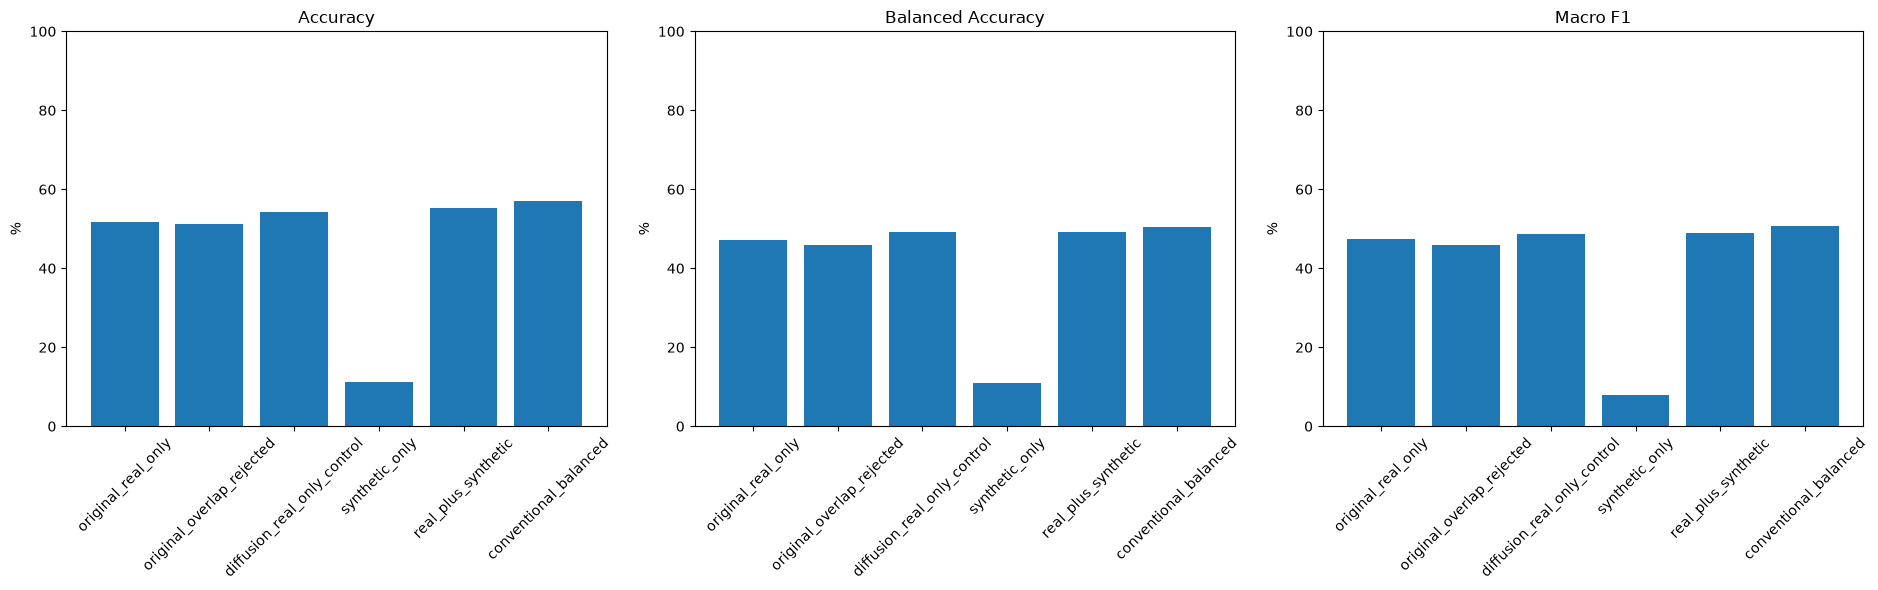

20 least frequent real classes:
           conventional_balanced  diffusion_real_only_control  original_overlap_rejected  original_real_only  real_plus_synthetic  synthetic_only  real  filtered_minus_original_pp  diffusion_real_only_control_minus_original_pp  augmented_minus_real_pp  synthetic_minus_real_pp  conventional_balanced_minus_original_pp
class                                                                                                                                                                                                                                                                                                                        
pine_tree                 0.1000                       0.2000                     0.0000              0.2000               0.0000          0.1000    41                    -20.0000                                         0.0000                 -20.0000                 -10.0000                                 -10.0000
bottle        

In [189]:
metrics = ['accuracy', 'balanced_accuracy', 'macro_precision', 'macro_recall',
           'macro_f1', 'macro_roc_auc', 'macro_pr_auc']
indexed = comparison.set_index('data')
changes = indexed.drop(index='original_real_only')[metrics].subtract(
    indexed.loc['original_real_only', metrics], axis='columns') * 100
changes.to_csv(SAVE_DIR / 'results' / 'all_experiments_minus_original_percentage_points.csv')
print('Change vs original real-only (percentage points):')
print(changes.round(3).to_string())

fig, axes = plt.subplots(1, 3, figsize=(19, 6))
for ax, metric in zip(axes, ['accuracy', 'balanced_accuracy', 'macro_f1']):
    ax.bar(comparison['data'], 100 * comparison[metric])
    ax.set_title(metric.replace('_', ' ').title())
    ax.set_ylabel('%')
    ax.set_ylim(0, 100)
    ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.savefig(SAVE_DIR / 'results' / 'six_experiment_test_comparison.png', dpi=150)
plt.show()

per_class = pd.DataFrame(class_results)
recalls = per_class.pivot(index='class', columns='data', values='recall')
recalls = recalls.join(class_counts.set_index('class')['real']).sort_values('real')
recalls['filtered_minus_original_pp'] = 100 * (recalls['original_overlap_rejected'] - recalls['original_real_only'])
recalls[f'{third_name}_minus_original_pp'] = 100 * (recalls[third_name] - recalls['original_real_only'])
recalls['augmented_minus_real_pp'] = 100 * (recalls['real_plus_synthetic'] - recalls['original_real_only'])
recalls['synthetic_minus_real_pp'] = 100 * (recalls['synthetic_only'] - recalls['original_real_only'])
recalls['conventional_balanced_minus_original_pp'] = 100 * (recalls['conventional_balanced'] - recalls['original_real_only'])
recalls.to_csv(SAVE_DIR / 'results' / 'per_class_recall_comparison.csv')
print('20 least frequent real classes:')
print(recalls.head(20).round(4).to_string())
print('Results directory:', SAVE_DIR / 'results')

# Direct comparison of conventional augmentation with each of the five earlier runs.
conventional_vs_earlier = pd.DataFrame({
    metric: 100 * (indexed.loc['conventional_balanced', metric]
                   - indexed.drop(index='conventional_balanced')[metric])
    for metric in metrics
})
conventional_vs_earlier.index.name = 'earlier_experiment'
conventional_vs_earlier.to_csv(
    SAVE_DIR / 'results' / 'conventional_vs_earlier_percentage_points.csv'
)
print('Conventional-balanced minus each earlier model (percentage points):')
print(conventional_vs_earlier.round(3).to_string())

conventional_class_vs_earlier = pd.DataFrame({
    name: 100 * (recalls['conventional_balanced'] - recalls[name])
    for name in EXPERIMENT_NAMES if name != 'conventional_balanced'
})
conventional_class_vs_earlier.to_csv(
    SAVE_DIR / 'results' / 'conventional_vs_earlier_per_class_pp.csv'
)


## 14. Interpretation and limitations

- All six final classifiers use one fixed test manifest, with no test images used during training, OOF rejection, diffusion, or conventional augmentation. Compatible checkpoints from the same fixed-split pipeline may be resumed; historical scores from different splits are not reused.
- The baseline repeat uses the same data but a different seed. It is not an additional data-treatment condition. The optional filtered-plus-synthetic mode replaces that repeat with a fifth distinct treatment.
- The dataset was used in earlier experiments, so this is not a genuinely independent external benchmark. Path disjointness does not detect duplicate visual content at different paths.
- Generated labels are conditions rather than verified annotations. Inspect samples for fidelity, diversity and memorization. Class-balanced diffusion sampling can oversample rare real examples.
- Conventional augmentation balances to the maximum original training-class count. It adds correlated transformed copies, not independently collected images. The sixth run retains all real images (no overlap rejection or diffusion). Its augmentation strengths are fixed in advance; do not tune them on test results.
- Equal epochs are not compute-matched. Multiple seeds per condition and a compute-matched control are needed for stronger claims.
- Scores are generated only when this notebook is executed. Do not tune against the held-out test scores.

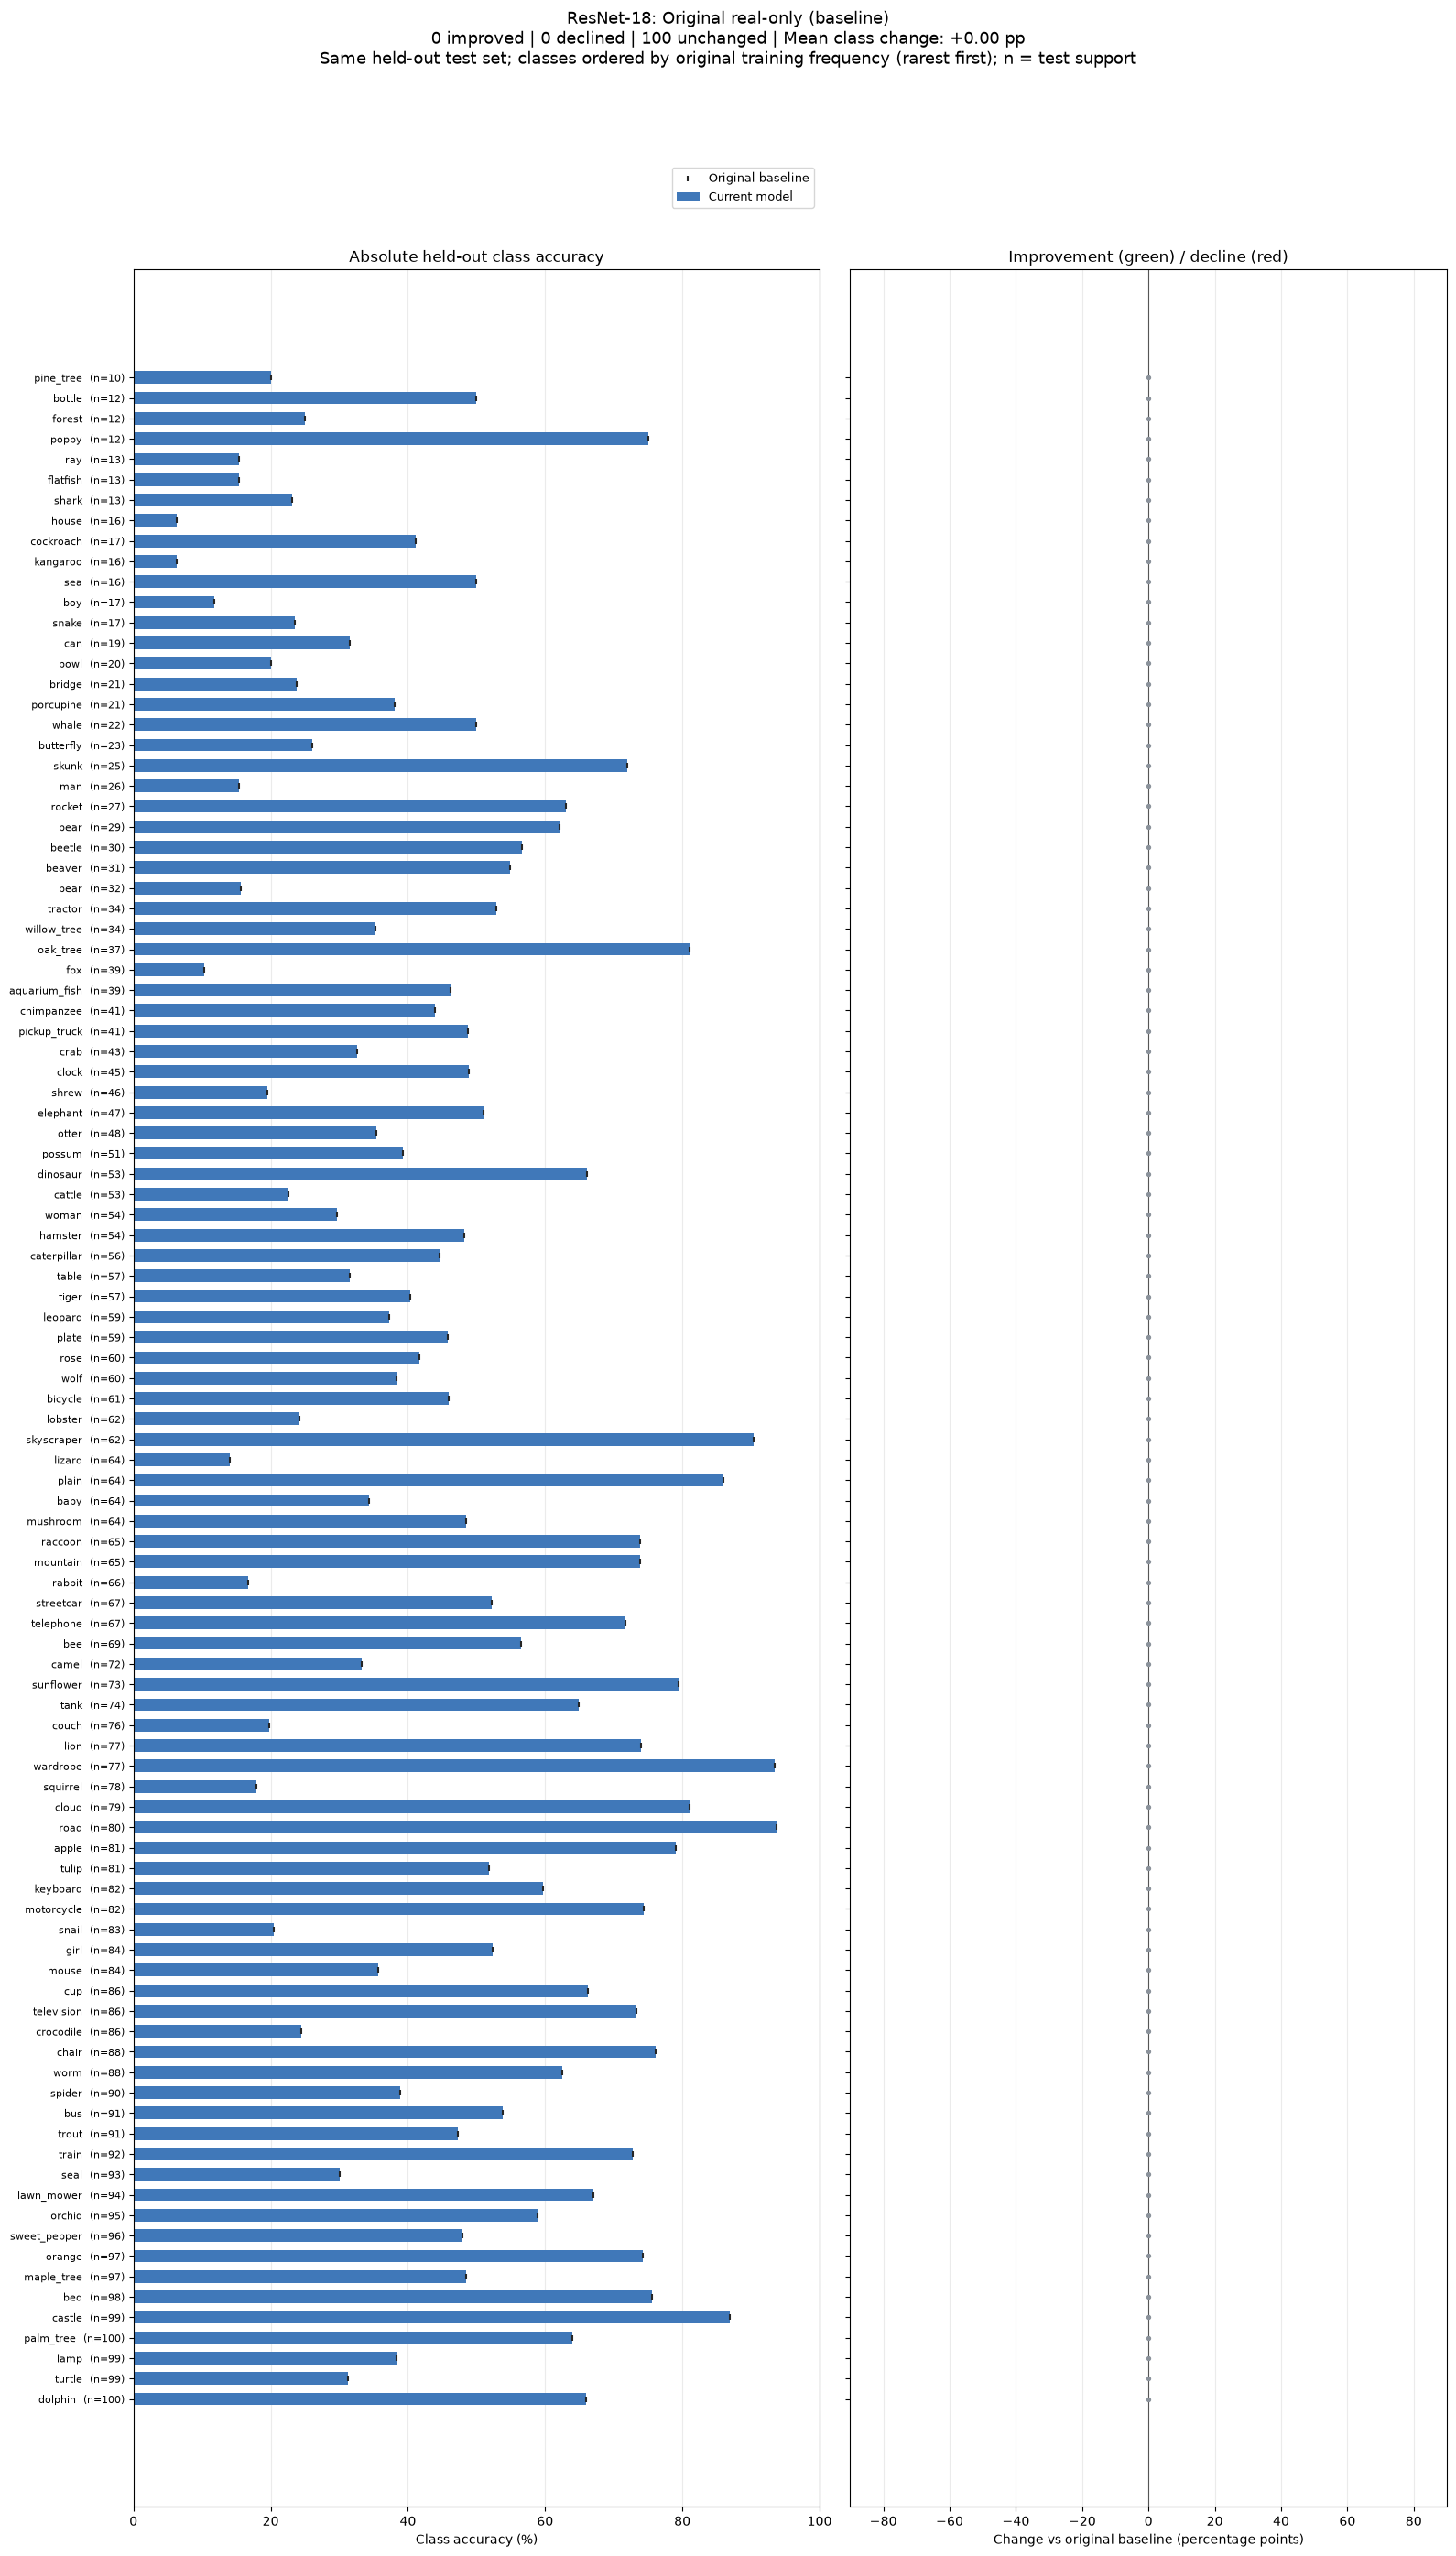

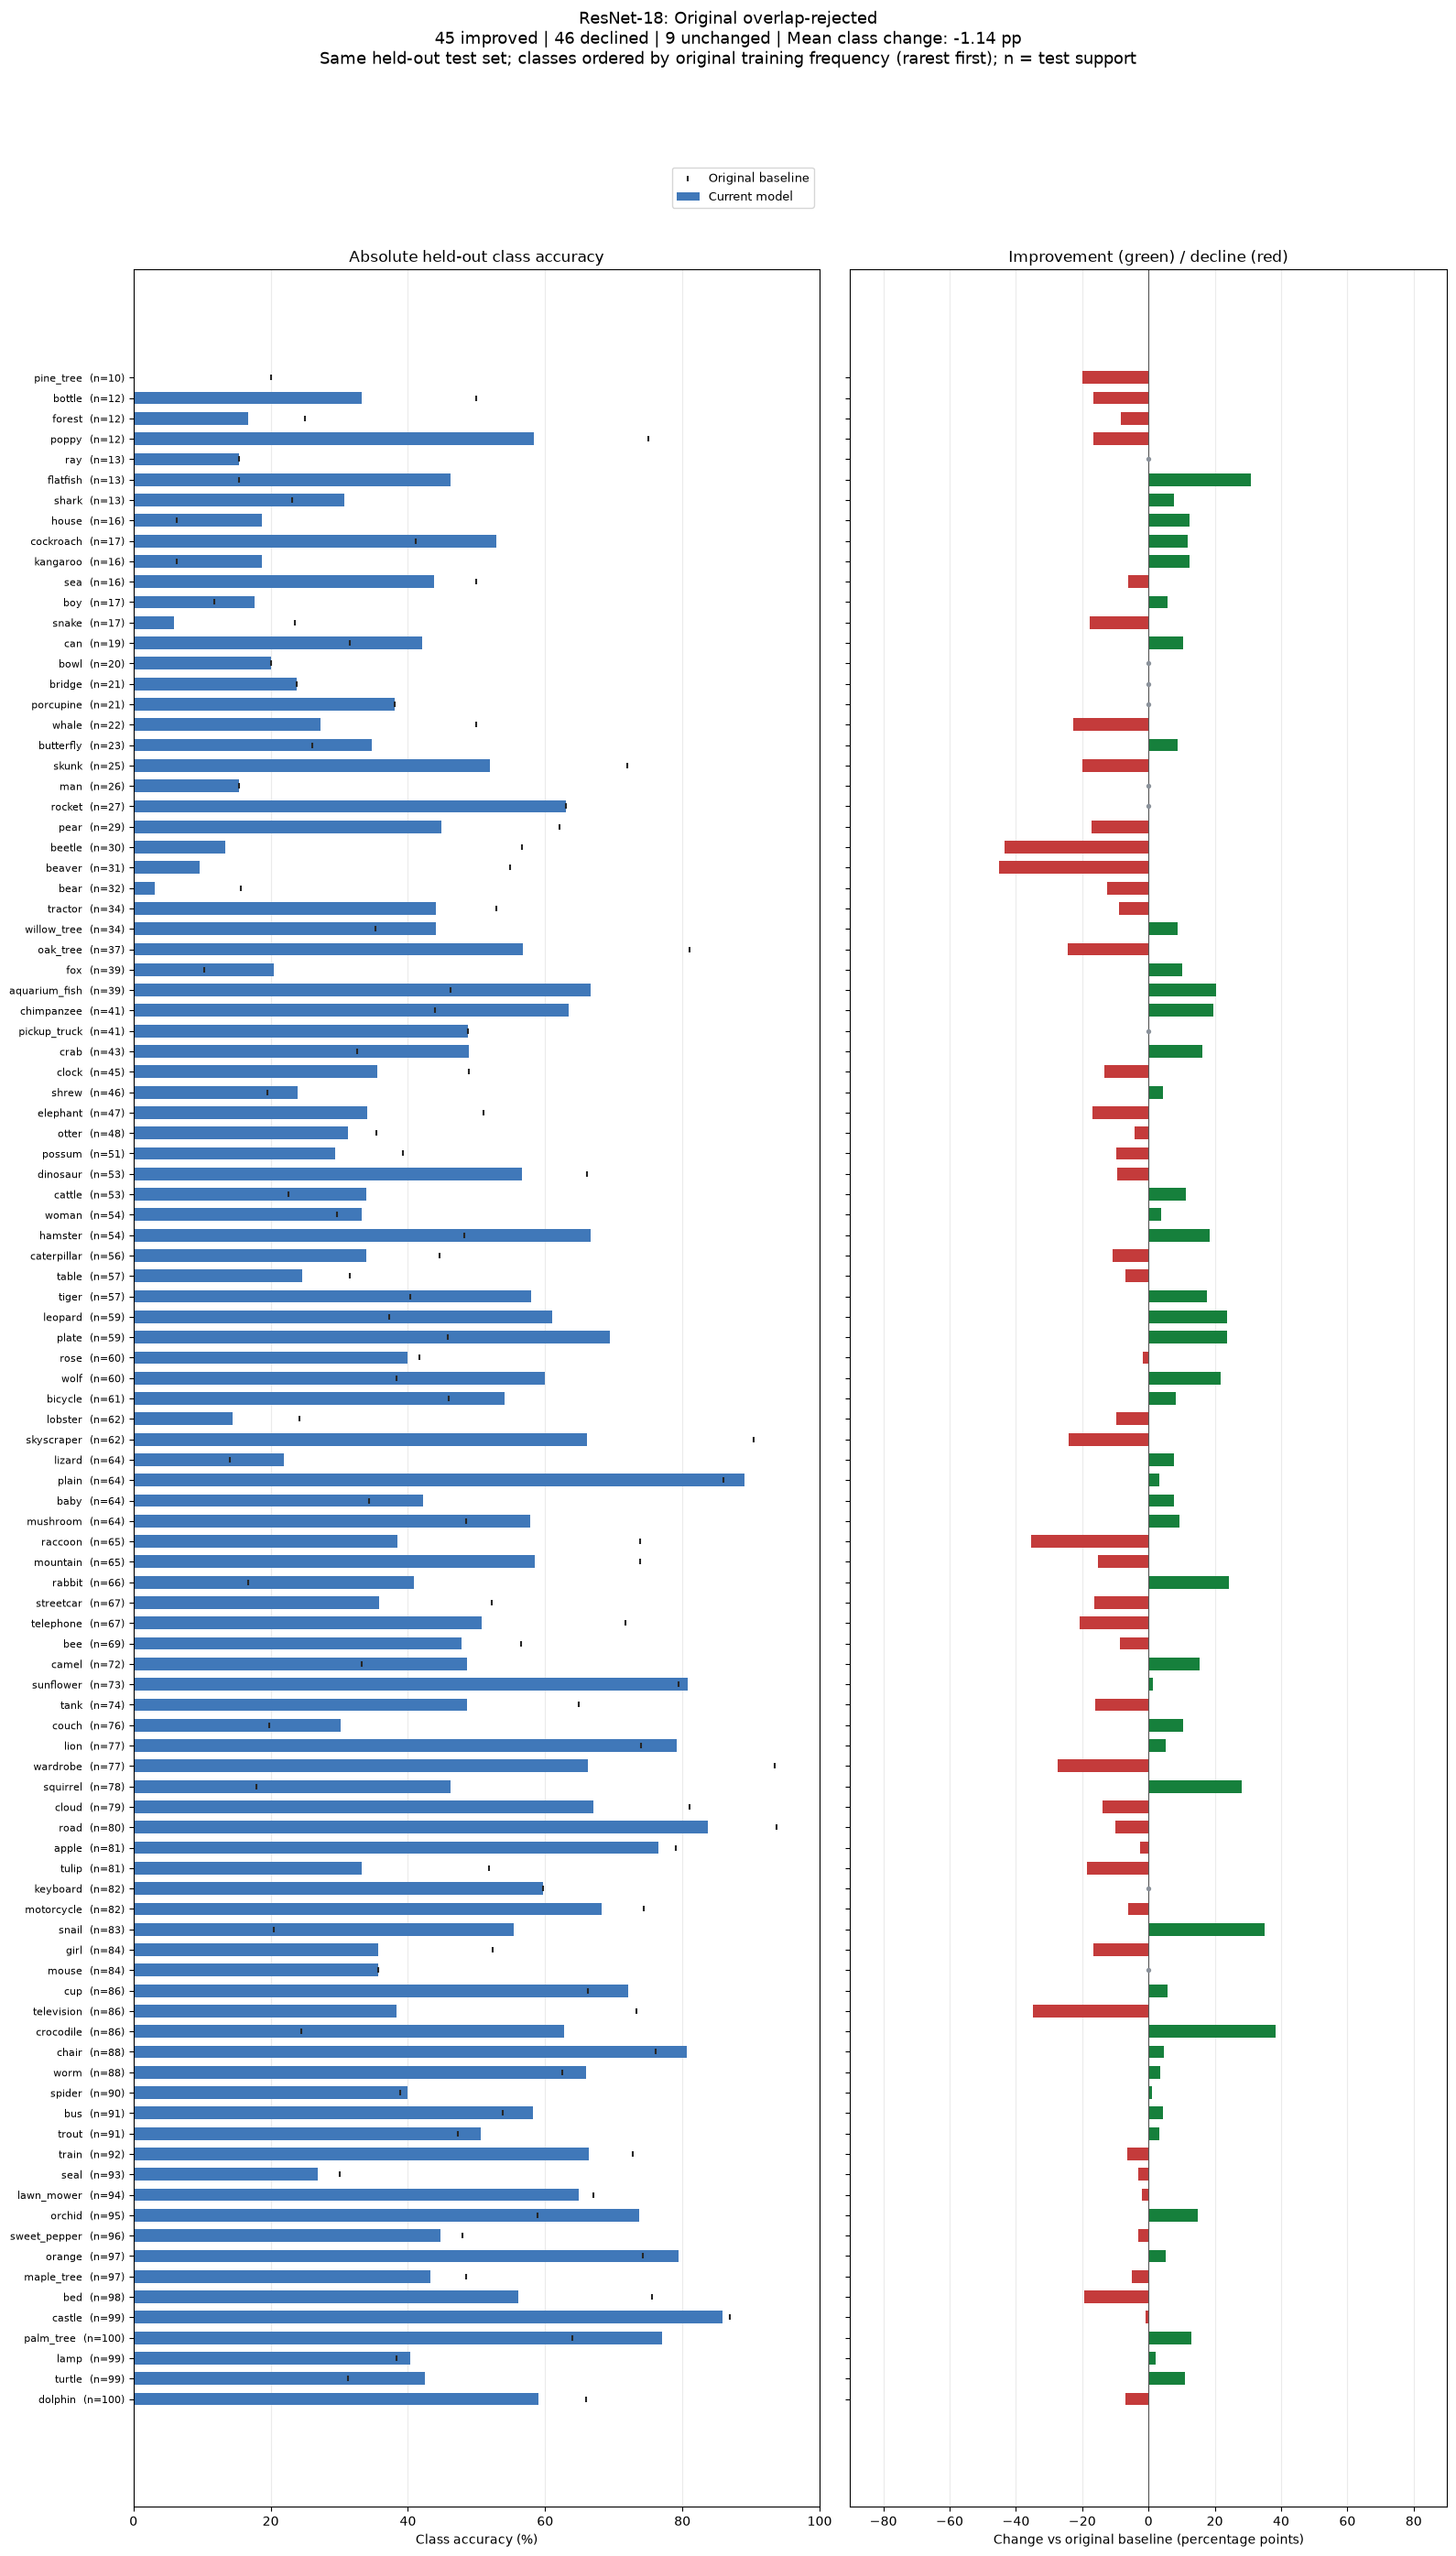

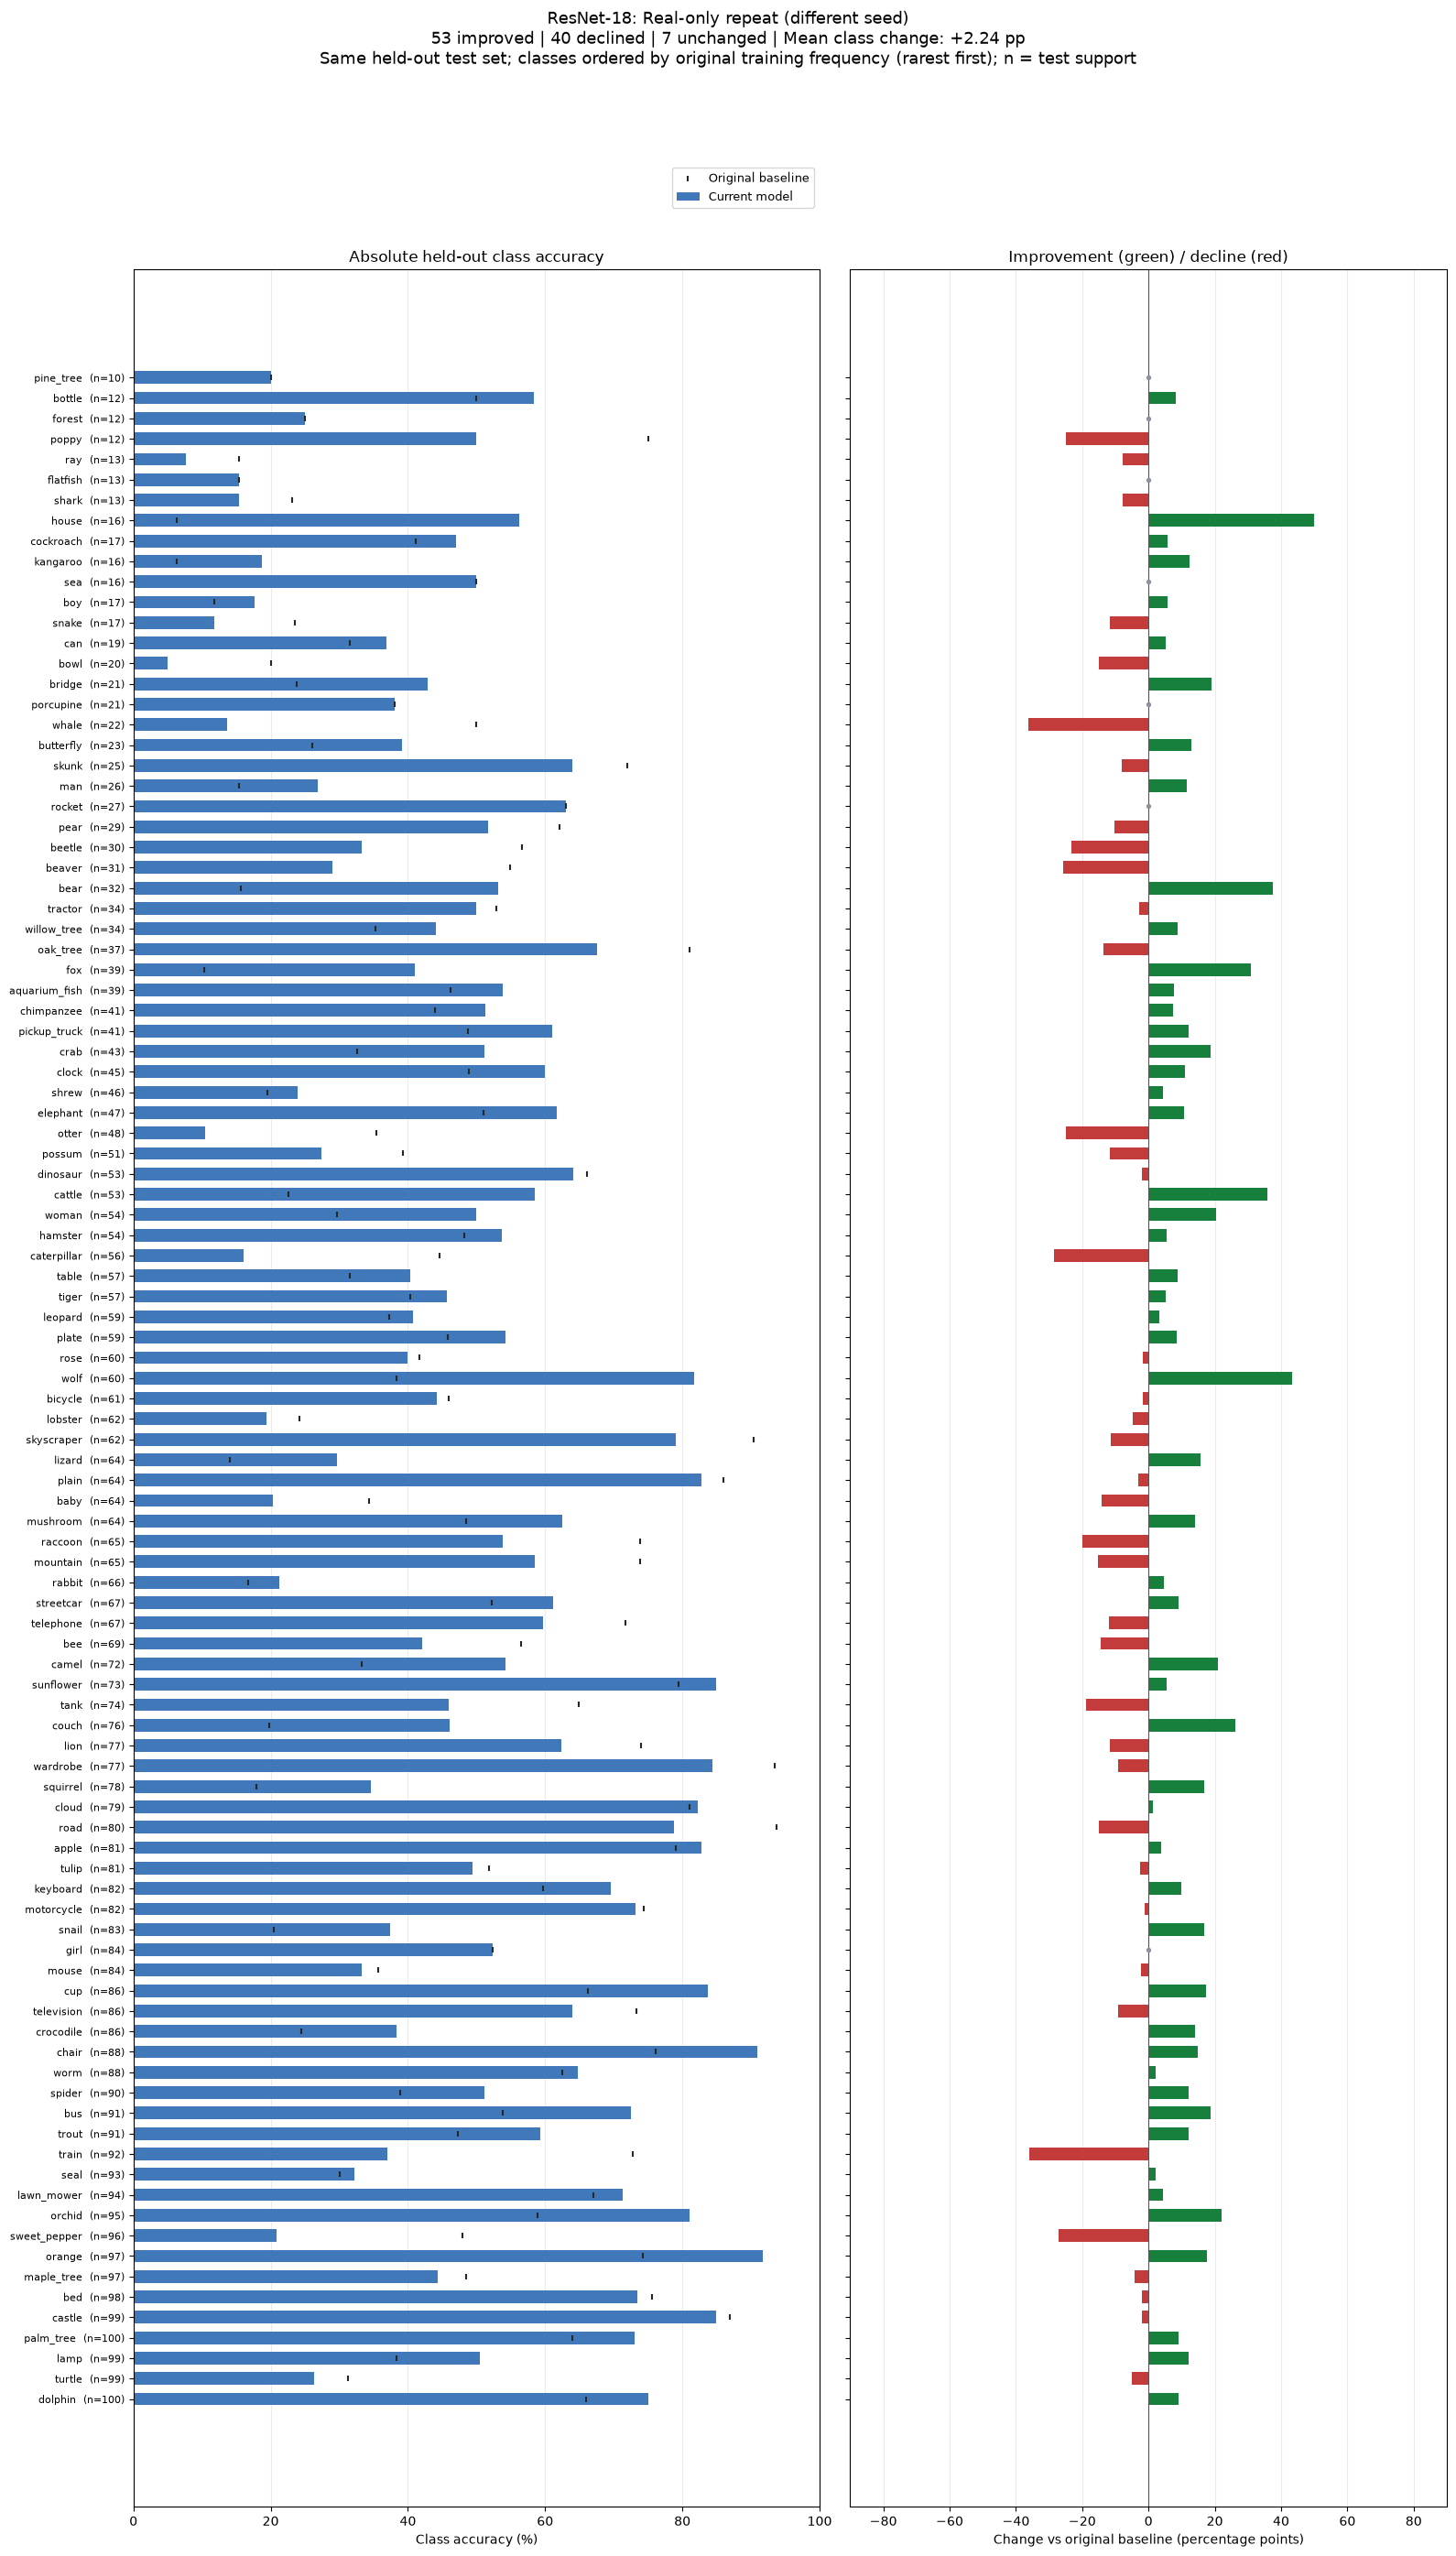

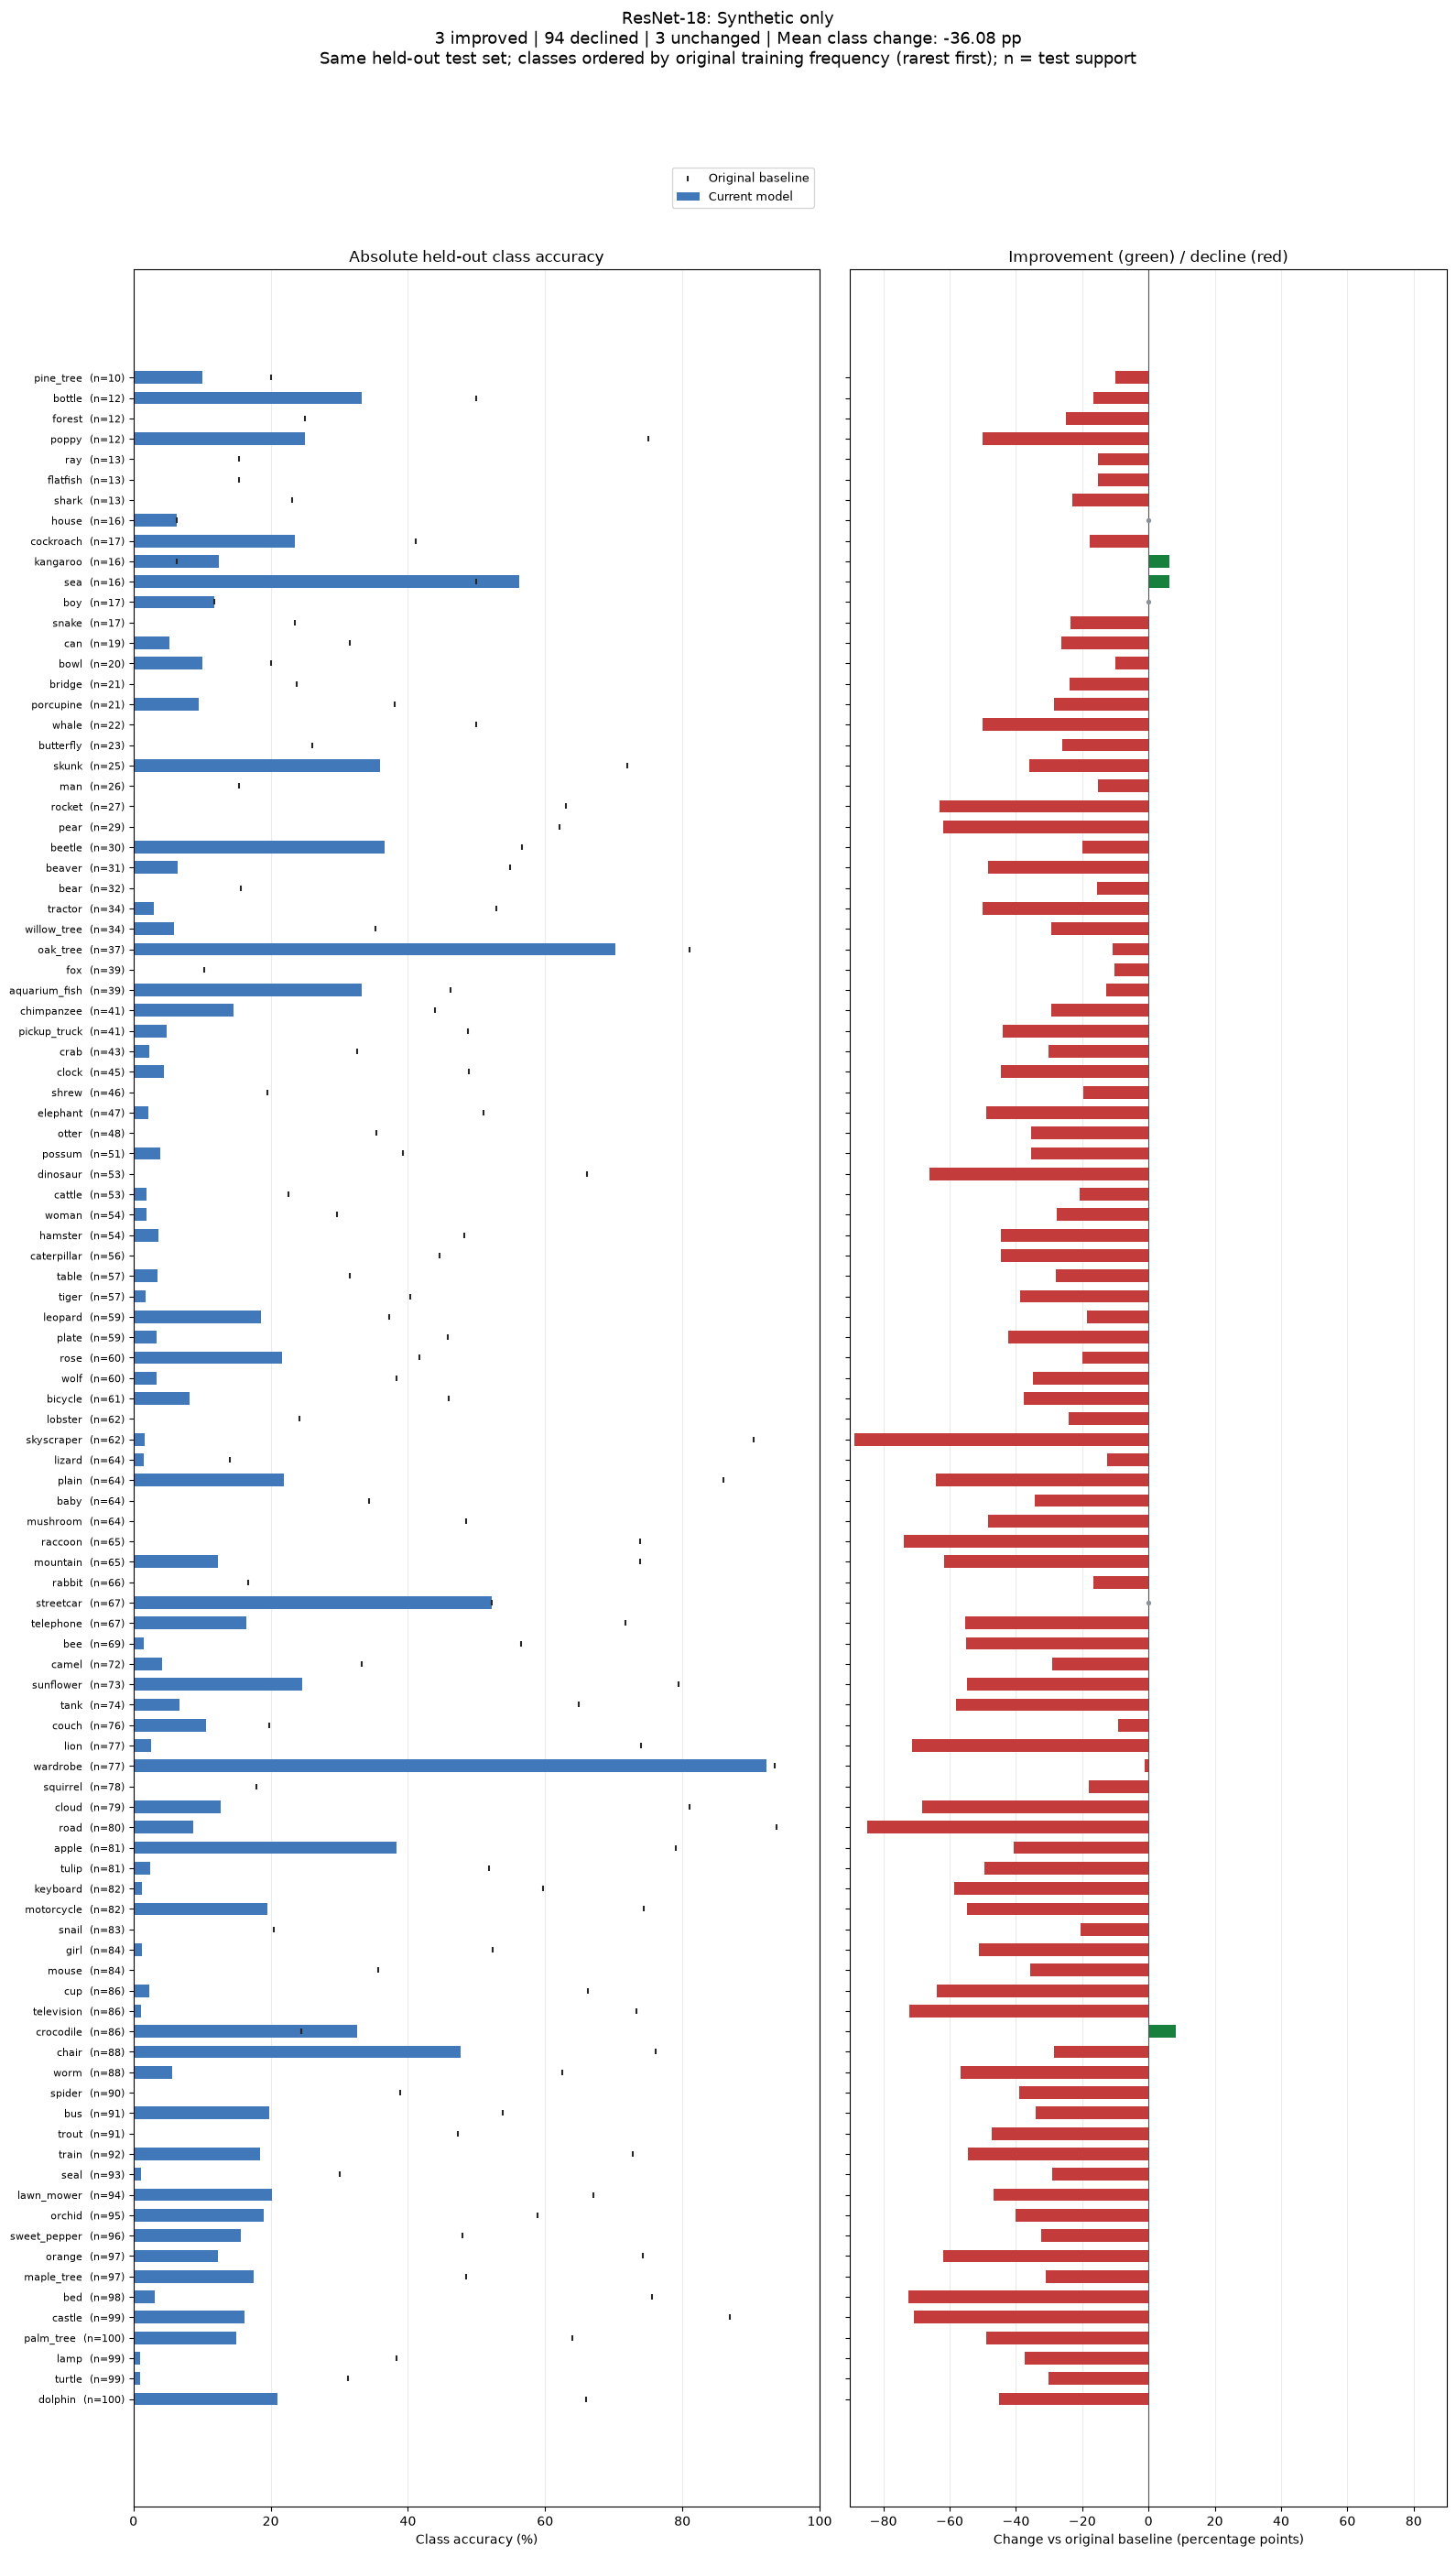

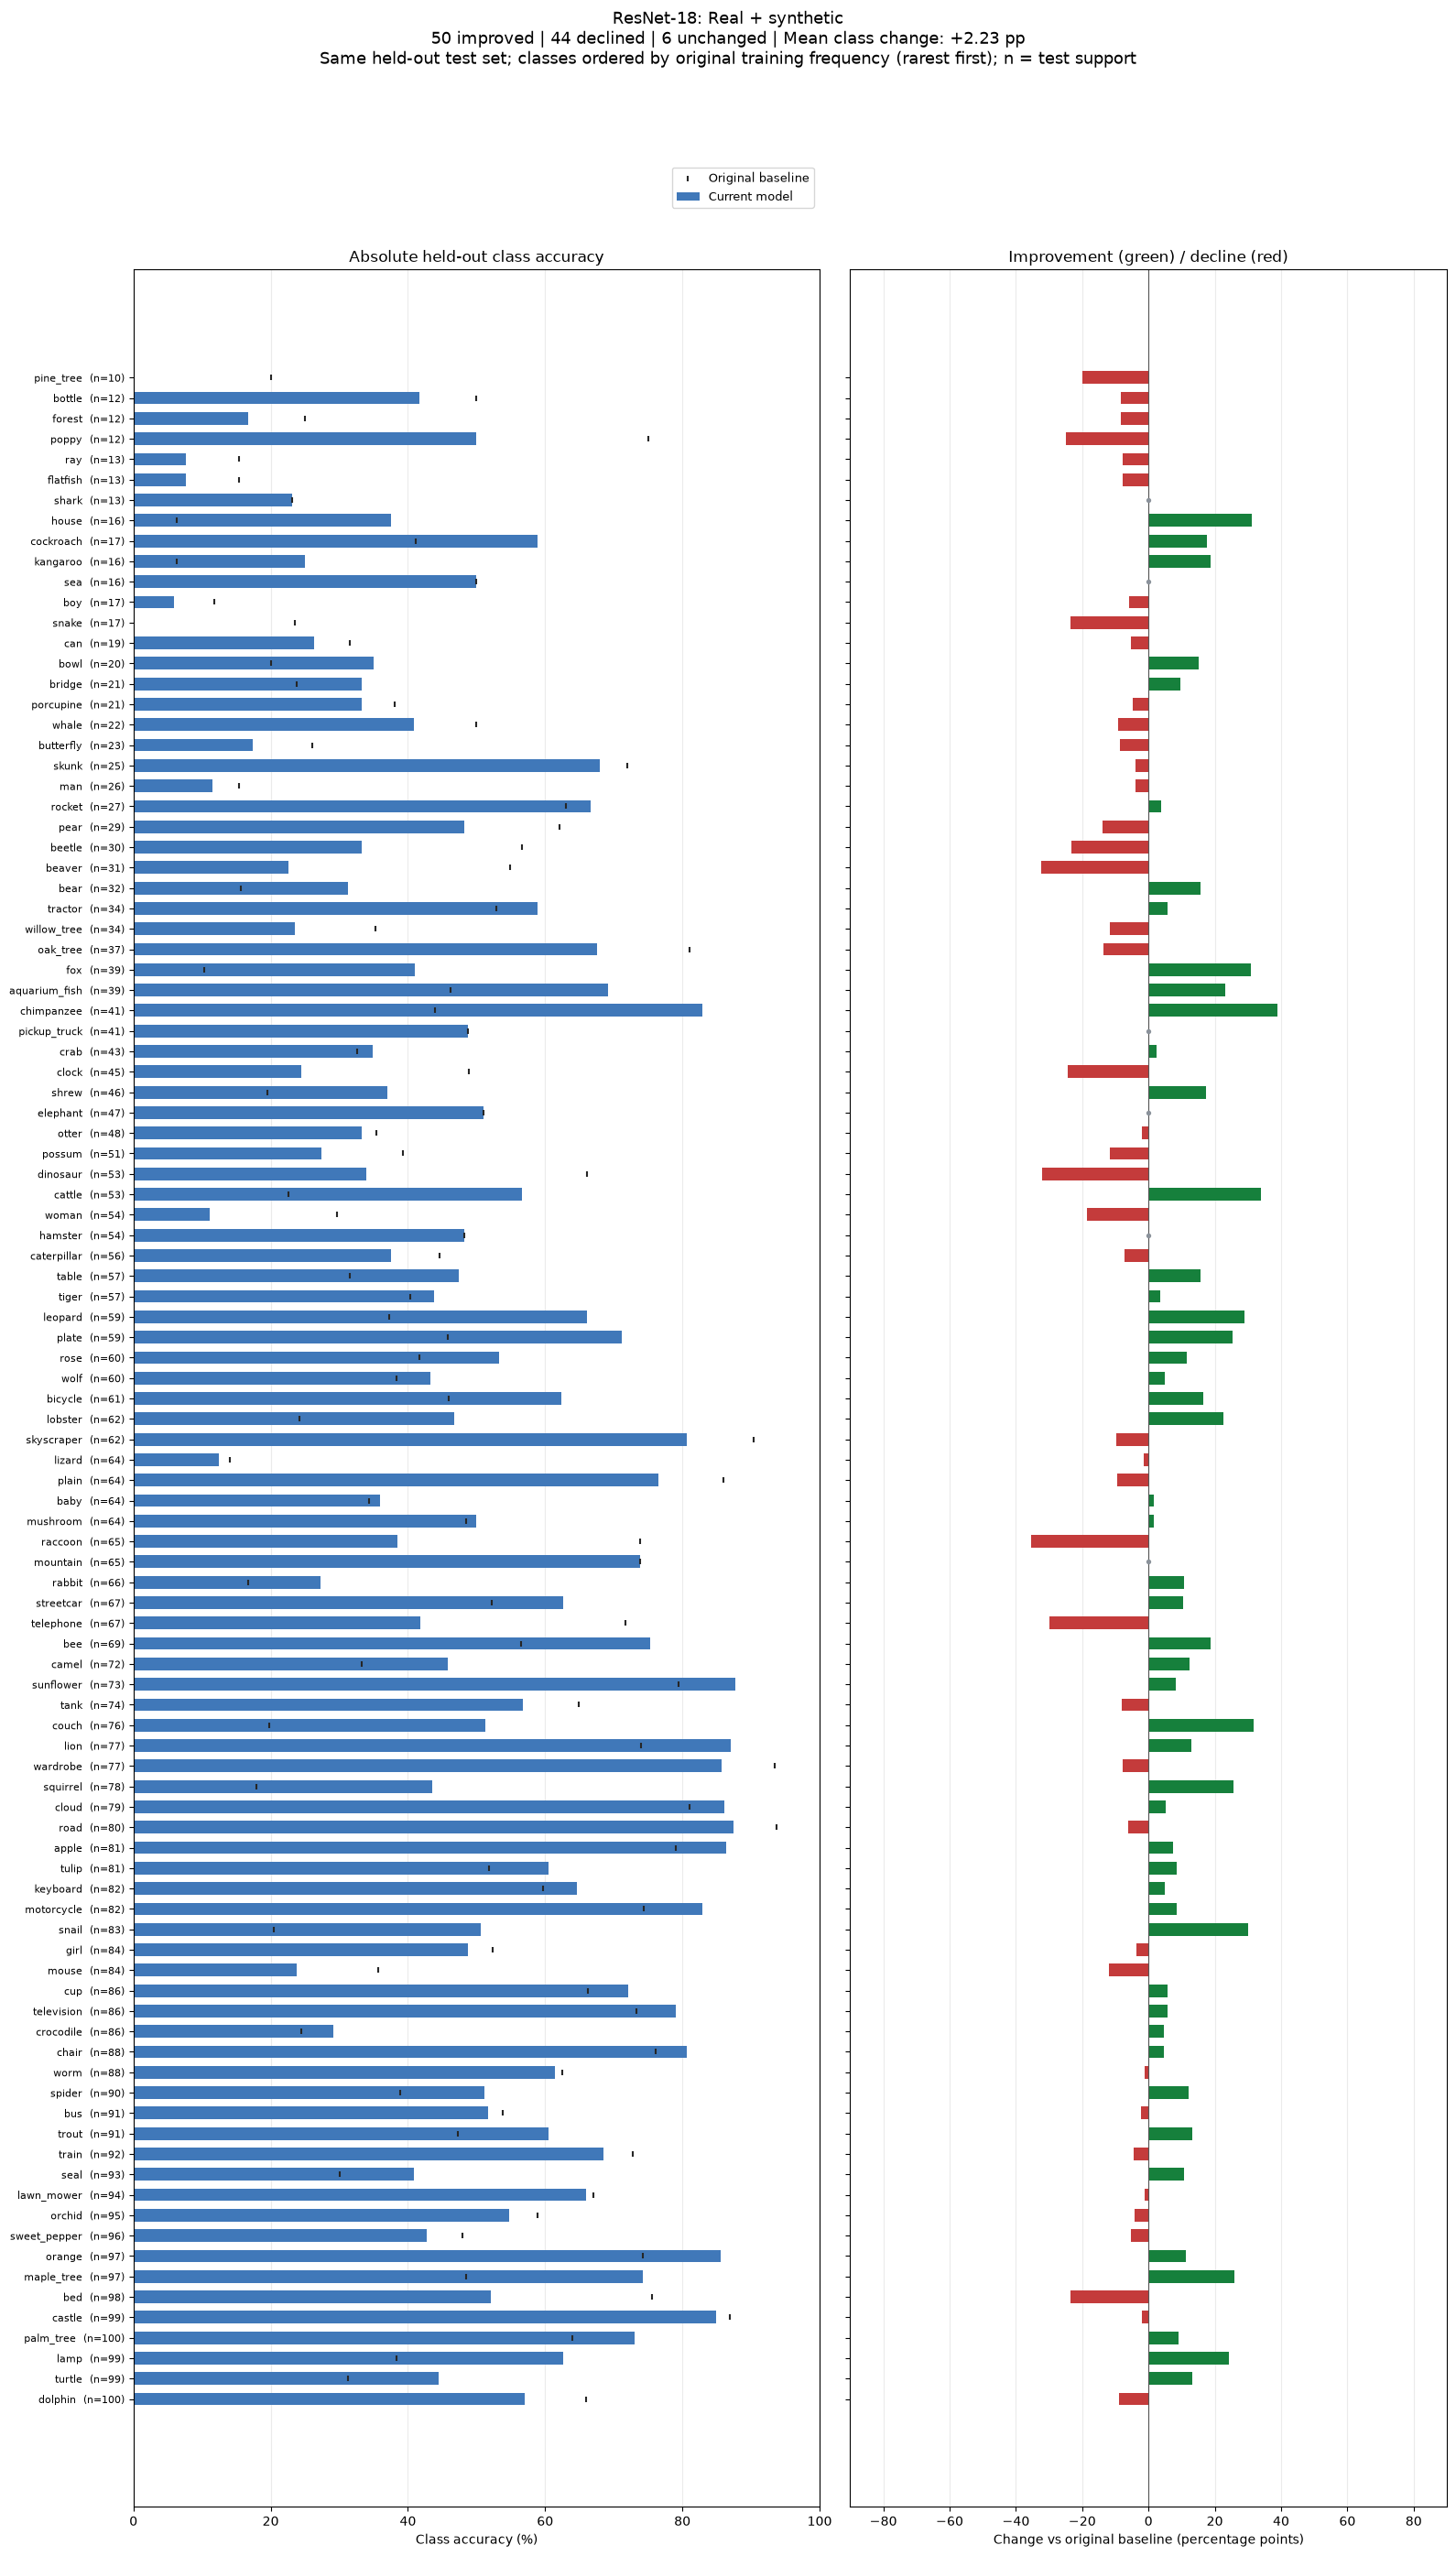

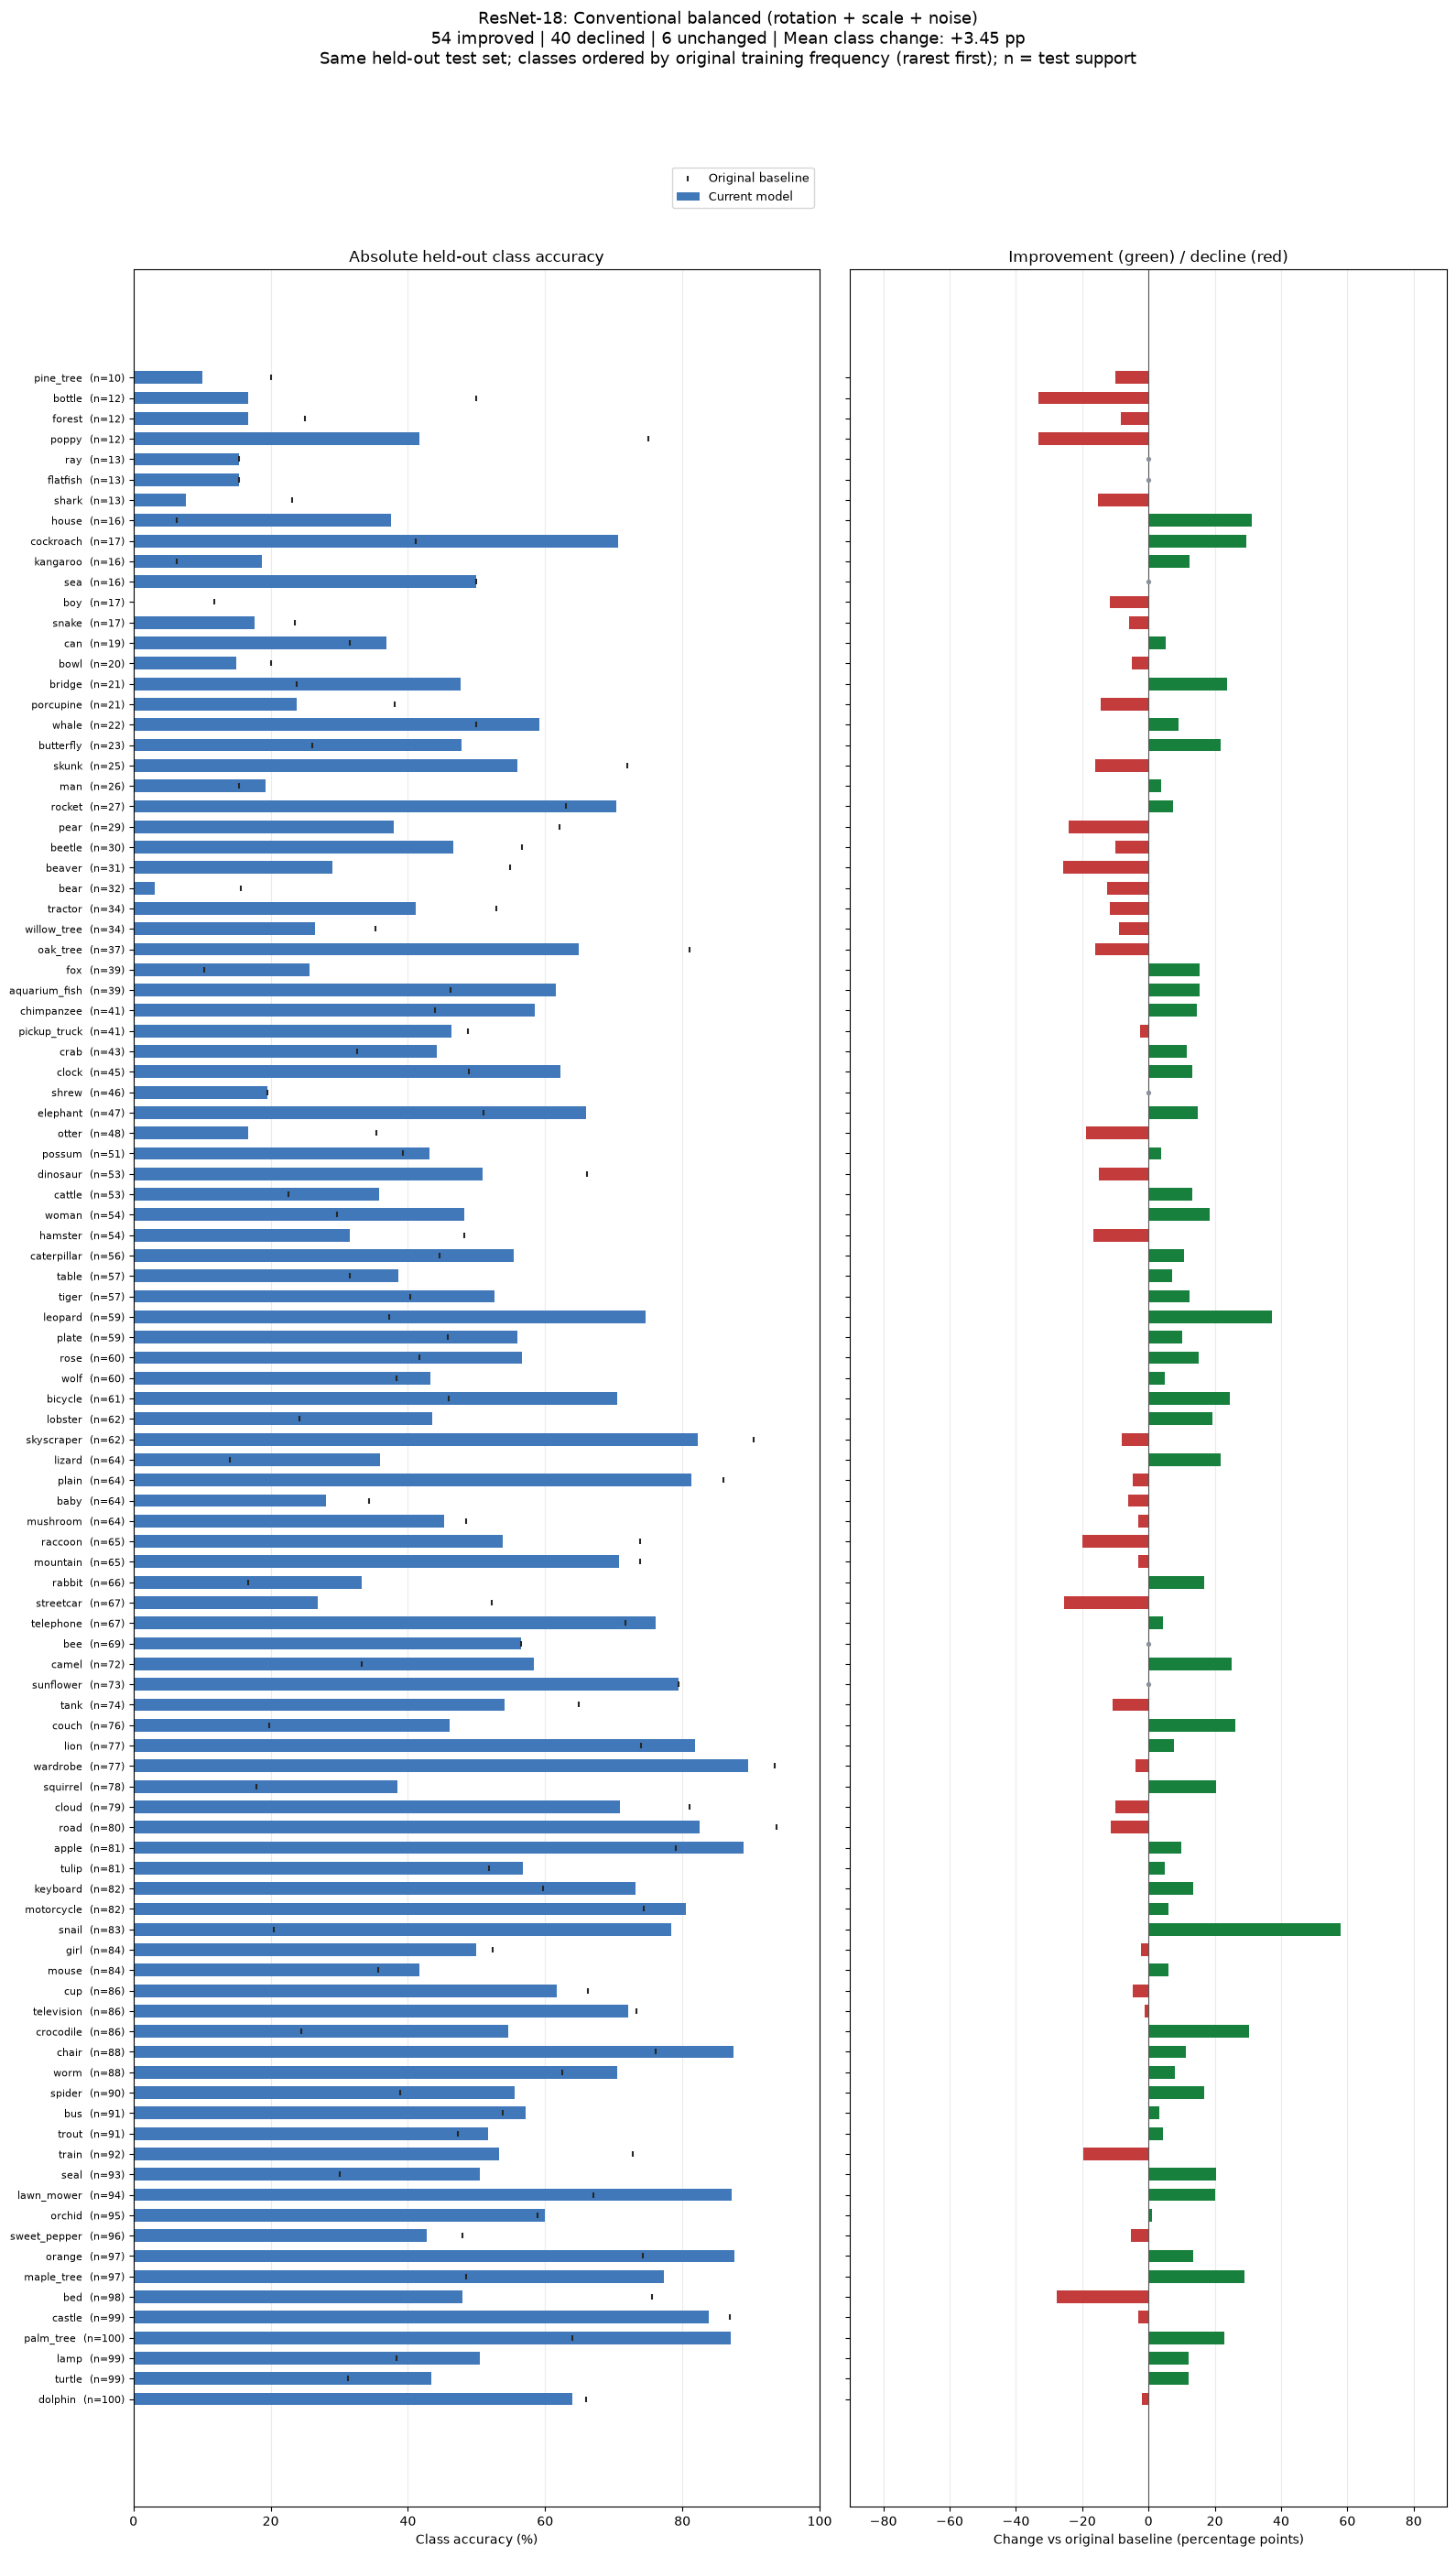

Saved 6 class-wise accuracy figures and CSV to /home/sidhant/1st Sem/FML/cifar100_lt_five_experiments_runs/_local_reuse/results/class_accuracy_plots


In [190]:
# 15. Class-wise test accuracy improvements: one figure per final model
# Class accuracy = correct predictions / test samples of that true class (recall).
# This is a post-evaluation analysis only; no retraining or test-set tuning.
baseline_name = 'original_real_only'
experiment_order = list(EXPERIMENT_NAMES)
if len(experiment_order) != 6 or baseline_name not in experiment_order:
    raise ValueError('Expected six final experiments, including the original baseline.')

class_accuracy_metrics = pd.DataFrame(class_results)
class_accuracy_metrics = class_accuracy_metrics.loc[
    class_accuracy_metrics['model'].eq('resnet18')
    & class_accuracy_metrics['data'].isin(experiment_order)
].copy()
if class_accuracy_metrics.duplicated(['data', 'class']).any():
    raise ValueError('Duplicate experiment/class evaluation results.')

# Use the same class order and support for every model.
class_accuracy_train_counts = train_pool['label'].value_counts().reindex(class_names)
class_accuracy_order = class_accuracy_train_counts.sort_values(kind='stable').index
class_accuracy_pct = 100 * class_accuracy_metrics.pivot(
    index='class', columns='data', values='recall'
).reindex(index=class_accuracy_order, columns=experiment_order)
class_accuracy_support = class_accuracy_metrics.pivot(
    index='class', columns='data', values='support'
).reindex(index=class_accuracy_order, columns=experiment_order)
expected_support = test_data['label'].value_counts().reindex(class_accuracy_order)
if (class_accuracy_pct.isna().any().any()
        or not np.isfinite(class_accuracy_pct.to_numpy()).all()
        or not ((class_accuracy_pct >= 0) & (class_accuracy_pct <= 100)).all().all()
        or expected_support.isna().any() or (expected_support <= 0).any()
        or not class_accuracy_support.eq(expected_support, axis='index').all().all()
        or class_accuracy_train_counts.isna().any()):
    raise ValueError('Missing or inconsistent per-class held-out evaluation results.')

class_accuracy_delta_pp = class_accuracy_pct.subtract(
    class_accuracy_pct[baseline_name], axis='index'
)
class_accuracy_plot_dir = SAVE_DIR / 'results' / 'class_accuracy_plots'
class_accuracy_plot_dir.mkdir(parents=True, exist_ok=True)

# Save one tidy table covering all 100 classes and all six experiments.
class_accuracy_rows = []
for version in experiment_order:
    for label in class_accuracy_order:
        class_accuracy_rows.append({
            'model': 'resnet18', 'experiment': version, 'class': label,
            'original_train_count': int(class_accuracy_train_counts.loc[label]),
            'test_support': int(expected_support.loc[label]),
            'baseline_accuracy_pct': class_accuracy_pct.loc[label, baseline_name],
            'class_accuracy_pct': class_accuracy_pct.loc[label, version],
            'improvement_pp': class_accuracy_delta_pp.loc[label, version],
        })
pd.DataFrame(class_accuracy_rows).to_csv(
    class_accuracy_plot_dir / 'class_accuracy_improvements.csv', index=False
)

experiment_titles = {
    'original_real_only': 'Original real-only (baseline)',
    'original_overlap_rejected': 'Original overlap-rejected',
    'diffusion_real_only_control': 'Real-only repeat (different seed)',
    'filtered_plus_synthetic': 'Overlap-rejected + synthetic',
    'synthetic_only': 'Synthetic only',
    'real_plus_synthetic': 'Real + synthetic',
    'conventional_balanced': 'Conventional balanced (rotation + scale + noise)',
}
# A common symmetric delta scale makes all six figures comparable.
max_delta = np.abs(class_accuracy_delta_pp.to_numpy()).max()
delta_limit = max(10, int(np.ceil(max_delta / 10)) * 10)
positions = np.arange(len(class_accuracy_order))
baseline_accuracy = class_accuracy_pct[baseline_name].to_numpy()
class_tick_labels = [
    f'{label}  (n={int(expected_support.loc[label])})'
    for label in class_accuracy_order
]

for version in experiment_order:
    current_accuracy = class_accuracy_pct[version].to_numpy()
    delta = class_accuracy_delta_pp[version].to_numpy()
    colors = np.where(delta > 1e-9, '#16803c',
                      np.where(delta < -1e-9, '#c43b3b', '#8b929b'))
    improved = int((delta > 1e-9).sum())
    declined = int((delta < -1e-9).sum())
    unchanged = len(delta) - improved - declined
    fig, (ax_acc, ax_delta) = plt.subplots(
        1, 2, sharey=True, figsize=(16, max(12, 0.28 * len(positions))),
        gridspec_kw={'width_ratios': [1.15, 1]}
    )

    # Left: absolute accuracy with the reference model shown for context.
    ax_acc.barh(positions, current_accuracy, height=0.62,
                color='#4078b9', label='Current model')
    ax_acc.scatter(baseline_accuracy, positions, s=14, color='#262626',
                   marker='|', linewidths=1.5, zorder=3, label='Original baseline')
    ax_acc.set(yticks=positions, yticklabels=class_tick_labels,
               xlim=(0, 100), xlabel='Class accuracy (%)',
               title='Absolute held-out class accuracy')
    ax_acc.tick_params(axis='y', labelsize=8)
    ax_acc.invert_yaxis()
    ax_acc.legend(loc='lower right', bbox_to_anchor=(1, 1.025), fontsize=9)
    ax_acc.grid(axis='x', alpha=0.25)
    ax_acc.set_axisbelow(True)

    # Right: signed percentage-point improvement relative to original real-only.
    ax_delta.barh(positions, delta, height=0.62, color=colors)
    ax_delta.scatter(np.zeros(unchanged), positions[np.abs(delta) <= 1e-9],
                     color='#8b929b', s=8, zorder=3)
    ax_delta.axvline(0, color='#555555', linewidth=0.8)
    ax_delta.set(xlim=(-delta_limit, delta_limit),
                 xlabel='Change vs original baseline (percentage points)',
                 title='Improvement (green) / decline (red)')
    ax_delta.grid(axis='x', alpha=0.25)
    ax_delta.set_axisbelow(True)

    fig.suptitle(
        f'ResNet-18: {experiment_titles.get(version, version)}\n'
        f'{improved} improved | {declined} declined | {unchanged} unchanged | '
        f'Mean class change: {delta.mean():+.2f} pp\n'
        'Same held-out test set; classes ordered by original training frequency '
        '(rarest first); n = test support',
        fontsize=13, y=0.995
    )
    fig.tight_layout(rect=(0, 0, 1, 0.965))
    fig.savefig(class_accuracy_plot_dir / f'{version}_class_accuracy.png',
                dpi=180, bbox_inches='tight')
    plt.show()
    plt.close(fig)

print(f'Saved {len(experiment_order)} class-wise accuracy figures and CSV to '
      f'{class_accuracy_plot_dir}')


## 16. Final performance metrics (paper-style comparison)

Compare all six final ResNet-18 experiments on the **same held-out test set**. No additional training or inference is required.

- **Maj:Min:** largest divided by smallest class count in the actual training manifest of each model (including generated or conventionally augmented images where applicable). A missing class gives an infinite ratio.
- **Overall Acc.:** fraction of held-out examples correctly classified.
- **Macro Acc.:** unweighted mean of all 100 class accuracies (per-class recall; balanced accuracy).
- **Min. Acc. / Maj. Acc.:** unweighted mean recall over the rarest / most frequent 20% of classes, ranked by the **original** training split. The groups are fixed for every model; ties are broken by class ID. Change `TAIL_FRACTION` if a different group definition is required.
- **Macro F1:** unweighted mean F1 over all classes.
- **ROC-AUC:** macro-average one-vs-rest ROC-AUC using predicted probabilities.

All performance scores are shown as percentages; the imbalance ratio is displayed as `ratio:1`. The exact paper's minority/majority grouping is not specified in the supplied metric labels, so the 20% definition is an explicit convention for this notebook.

In [192]:
# Paper-style comparison: one row per metric, one column per final experiment.
from IPython.display import display

TAIL_FRACTION = 0.20  # bottom/top 20% of original training classes
if not 0 < TAIL_FRACTION <= 0.5:
    raise ValueError('TAIL_FRACTION must be in (0, 0.5].')

metric_experiments = list(EXPERIMENT_NAMES)
metric_order = ['Maj:Min', 'Overall Acc.', 'Macro Acc.', 'Min. Acc.',
                'Maj. Acc.', 'Macro F1', 'ROC-AUC']
metric_class_ids = np.arange(NUM_CLASSES)
original_counts = train_pool['target'].value_counts().reindex(metric_class_ids, fill_value=0)
if (original_counts <= 0).any():
    raise ValueError('Original training split must contain every class.')
ranked_classes = sorted(metric_class_ids, key=lambda c: (original_counts.loc[c], c))
group_size = max(1, int(np.floor(NUM_CLASSES * TAIL_FRACTION)))
minority_ids = ranked_classes[:group_size]
majority_ids = ranked_classes[-group_size:]
assert not set(minority_ids).intersection(majority_ids)
minority_names = [class_names[c] for c in minority_ids]
majority_names = [class_names[c] for c in majority_ids]

# Reuse the metrics and per-class recalls computed by the held-out evaluation.
metric_summary = comparison.loc[comparison['model'].eq('resnet18')].set_index('data')
if not metric_summary.index.is_unique or set(metric_summary.index) != set(metric_experiments):
    raise ValueError('Run the held-out evaluation for all six experiments first.')
metric_per_class = pd.DataFrame(class_results)
metric_per_class = metric_per_class.loc[metric_per_class['model'].eq('resnet18')]
metric_recalls = metric_per_class.pivot(index='class', columns='data', values='recall').reindex(
    index=class_names, columns=metric_experiments)
metric_support = metric_per_class.pivot(index='class', columns='data', values='support').reindex(
    index=class_names, columns=metric_experiments)
metric_expected_support = test_data['label'].value_counts().reindex(class_names)
if (not np.isfinite(metric_recalls.to_numpy()).all()
        or not metric_support.eq(metric_expected_support, axis='index').all().all()
        or metric_expected_support.isna().any() or (metric_expected_support <= 0).any()):
    raise ValueError('Incomplete or inconsistent held-out per-class results.')

# Use the verified training manifest from the actual checkpoint origin, not the
# test distribution and not the current generated-image folders.
metric_records = {row['data']: row for row in records}
if set(metric_records) != set(metric_experiments):
    raise ValueError('Missing frozen training records.')
metric_values = {}
for experiment in metric_experiments:
    record = metric_records[experiment]
    origin = SOURCE_RUN if record['checkpoint_origin'] == 'archive' else SAVE_DIR
    manifest = origin / 'splits' / 'experiments' / f'{experiment}.csv'
    if sha256_file(manifest) != record['training_manifest_sha256']:
        raise RuntimeError(f'Training manifest changed: {experiment}')
    training_targets = pd.read_csv(require_materialized(manifest), usecols=['target'])['target']
    if len(training_targets) != record['train_images'] or not training_targets.isin(metric_class_ids).all():
        raise ValueError(f'Invalid training targets: {experiment}')
    counts = training_targets.value_counts().reindex(metric_class_ids, fill_value=0)
    ratio = float(counts.max() / counts.min()) if counts.min() > 0 else np.inf
    scores = metric_summary.loc[experiment]
    recalls = metric_recalls[experiment]
    if not np.isclose(recalls.mean(), scores['balanced_accuracy']):
        raise ValueError(f'Macro accuracy mismatch: {experiment}')
    metric_values[experiment] = [
        ratio,
        100 * scores['accuracy'],
        100 * recalls.mean(),
        100 * recalls.loc[minority_names].mean(),
        100 * recalls.loc[majority_names].mean(),
        100 * scores['macro_f1'],
        100 * scores['macro_roc_auc'],
    ]

paper_metrics = pd.DataFrame(metric_values, index=metric_order)
paper_metrics.index.name = 'Metric'
if not np.isfinite(paper_metrics.iloc[1:].to_numpy()).all():
    raise ValueError('One or more performance metrics are missing or non-finite.')

# Keep numeric values in the CSV; format the displayed table for reporting.
metric_results_dir = SAVE_DIR / 'results'
metric_results_dir.mkdir(parents=True, exist_ok=True)
metric_csv = metric_results_dir / 'paper_style_metrics.csv'
paper_metrics.to_csv(metric_csv)
metric_groups = pd.DataFrame({
    'class': class_names,
    'class_id': metric_class_ids,
    'original_train_count': original_counts.to_numpy(),
    'group': ['minority' if c in minority_ids else 'majority' if c in majority_ids else 'middle'
              for c in metric_class_ids],
})
metric_groups.to_csv(metric_results_dir / 'paper_style_class_groups.csv', index=False)

metric_display = paper_metrics.astype(object)
for experiment in metric_experiments:
    metric_display.loc['Maj:Min', experiment] = f"{paper_metrics.loc['Maj:Min', experiment]:.2f}:1"
    for metric in metric_order[1:]:
        metric_display.loc[metric, experiment] = f'{paper_metrics.loc[metric, experiment]:.2f}%'
metric_titles = {
    'original_real_only': 'Original real-only',
    'original_overlap_rejected': 'Overlap-rejected',
    'diffusion_real_only_control': 'Real-only repeat',
    'filtered_plus_synthetic': 'Filtered + synthetic',
    'synthetic_only': 'Synthetic only',
    'real_plus_synthetic': 'Real + synthetic',
    'conventional_balanced': 'Conventional balanced',
}
print(f'Fixed held-out test set: {len(test_data):,} images | {NUM_CLASSES} classes')
print(f'Minority and majority: {group_size} classes each, based on original training frequency.')
display(metric_display.rename(columns=metric_titles))
print('Numeric metrics saved to:', metric_csv)
print('Class group definitions saved to:', metric_results_dir / 'paper_style_class_groups.csv')

Fixed held-out test set: 5,745 images | 100 classes
Minority and majority: 20 classes each, based on original training frequency.


,Original real-only,Overlap-rejected,Real-only repeat,Synthetic only,Real + synthetic,Conventional balanced
Metric,,,,,,
Maj:Min,9.73:1,9.95:1,9.73:1,1.00:1,2.49:1,1.00:1
Overall Acc.,51.71%,51.26%,54.27%,11.26%,55.39%,57.06%
Macro Acc.,47.06%,45.93%,49.30%,10.98%,49.30%,50.51%
Min. Acc.,31.22%,29.82%,31.64%,11.97%,28.91%,30.21%
Maj. Acc.,56.89%,57.83%,60.13%,13.42%,60.99%,64.22%
Macro F1,47.32%,45.80%,48.75%,7.89%,48.91%,50.77%
ROC-AUC,97.04%,96.75%,97.39%,80.23%,97.20%,97.24%


Numeric metrics saved to: /home/sidhant/1st Sem/FML/cifar100_lt_five_experiments_runs/_local_reuse/results/paper_style_metrics.csv
Class group definitions saved to: /home/sidhant/1st Sem/FML/cifar100_lt_five_experiments_runs/_local_reuse/results/paper_style_class_groups.csv
